# Práctica 1 — Aprendizaje no supervisado: la paleta de los pintores

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Este es el cuaderno **de partida**. Contiene la información del entorno, las rutas de los datos de
**vuestro grupo** (cada grupo tiene sus propios cuadros), las funciones que la práctica
proporciona, la comprobación del sello y el esqueleto de secciones en el orden en que debéis
trabajar. **Todo lo marcado `TODO` es vuestro**, en código y en Markdown.

Leed el enunciado antes de empezar. Tres reglas deciden buena parte de la nota:

1. **La interpretación va en celdas Markdown**, no en comentarios de Python.
2. **El sello no supervisado cubre los Ejercicios 3 y 4.** El orden de abajo no se negocia y se
   evalúa: los metadatos (autor, época, título...) no se tocan hasta la revelación.
3. **En el Ejercicio 1 diseñáis y programáis vuestra propia variante de $K$-means** como estimador
   de scikit-learn, y la volvéis a usar en el Ejercicio 3.

## 0. Entorno y constantes fijadas por el curso

Ejecutad esto primero. Imprime las versiones con las que se obtuvieron los resultados, las tres
semillas del curso y vuestro número de grupo. **No cambiéis `P1_SEEDS`, `K_DIC` ni
`PIX_POR_CUADRO`**; `GRUPO` y `CUADROS_EJ1` se leen de `Datos/grupo.json`.

In [1]:
# --- Práctica 1: entorno y constantes fijadas por el curso ------------------
import os, platform, json, re
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt
from PIL import Image

P1_SEEDS = [13, 41, 97]        # las tres semillas fijadas por el curso: no se cambian
SEED = P1_SEEDS[0]             # la semilla única, donde haga falta una

DATOS = os.path.join("..", "Datos")            # carpeta de datos de vuestro grupo, relativa a este cuaderno
CUADROS_FILE = os.path.join(DATOS, "cuadros.csv")
CUADROS_DIR = os.path.join(DATOS, "cuadros")
# La ruta de los metadatos (autor, época...) NO se define aquí a propósito:
# es una constante de la etapa de revelación.

with open(os.path.join(DATOS, "grupo.json"), encoding="utf-8") as f:
    _grupo = json.load(f)
GRUPO = _grupo["grupo"]                   # cada grupo tiene su propio conjunto de cuadros
CUADROS_EJ1 = _grupo["CUADROS_EJ1"]       # row_id de los tres cuadros del Ejercicio 1
K_DIC = 24                     # tamaño del diccionario común de colores (Ejercicio 2)
PIX_POR_CUADRO = 2000          # píxeles de cada cuadro para ajustar el diccionario

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("scipy       ", scipy.__version__)
print("scikit-learn", sklearn.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("Pillow      ", Image.__version__)
print("P1_SEEDS    ", P1_SEEDS)
print("GRUPO       ", GRUPO, f"({_grupo['n_cuadros']} cuadros)")


python       3.13.5
numpy        2.1.3
scipy        1.15.3
scikit-learn 1.6.1
pandas       2.2.3
matplotlib   3.10.0
Pillow       11.3.0
P1_SEEDS     [13, 41, 97]
GRUPO        4 (56 cuadros)


Las funciones siguientes están **proporcionadas**: cargan los datos, comprueban un estimador y
dibujan paletas, rejillas de miniaturas, dendrogramas y mapas. Ninguna de ellas lee metadatos.

In [2]:
# --- PROPORCIONADO. No modifiquéis estas funciones. --------------------------
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from scipy.cluster.hierarchy import dendrogram


def cargar_cuadros(path=CUADROS_FILE):
    """Tabla de cuadros: row_id, fichero, ancho, alto. No contiene autor ni ningún metadato."""
    tab = pd.read_csv(path)
    assert list(tab.columns) == ["row_id", "fichero", "ancho", "alto"], list(tab.columns)
    return tab


def cargar_imagen(fichero):
    """Devuelve el cuadro como array uint8 de forma (alto, ancho, 3)."""
    return np.asarray(Image.open(os.path.join(CUADROS_DIR, fichero)).convert("RGB"))


def a_pixeles(img):
    """Imagen (alto, ancho, 3) en uint8 -> matriz (número de píxeles, 3) en [0, 1]."""
    return img.reshape(-1, 3).astype(float) / 255.0


def mostrar_paleta(ax, colores, proporciones):
    """Tira horizontal con los colores ordenados de mayor a menor proporción."""
    colores, proporciones = np.asarray(colores), np.asarray(proporciones, float)
    orden = np.argsort(-proporciones)
    izq = 0.0
    for c, p in zip(colores[orden], proporciones[orden] / proporciones.sum()):
        ax.barh(0, p, left=izq, color=np.clip(c, 0, 1), height=1.0)
        izq += p
    ax.set_xlim(0, 1); ax.set_ylim(-0.5, 0.5); ax.axis("off")


def rand_ajustado(a, b):
    """Índice de Rand ajustado entre DOS PARTICIONES vuestras (Tema 2), calculado a partir de la
    tabla de contingencia. Sirve para comparar particiones entre sí en los Ejercicios 1-4; la
    función equivalente de scikit-learn queda reservada a la revelación (el sello la vigila)."""
    _, ia = np.unique(a, return_inverse=True); _, ib = np.unique(b, return_inverse=True)
    T = np.zeros((ia.max() + 1, ib.max() + 1)); np.add.at(T, (ia, ib), 1)
    c2 = lambda x: x * (x - 1) / 2
    s, sa, sb, N = c2(T).sum(), c2(T.sum(1)).sum(), c2(T.sum(0)).sum(), c2(len(a))
    esperado = sa * sb / N
    return float((s - esperado) / (0.5 * (sa + sb) - esperado))


def comprobar_estimador(est, X):
    """Comprobaciones mínimas de que `est` es un estimador de agrupamiento de scikit-learn.
    No sustituye a sklearn.utils.estimator_checks.check_estimator, que podéis investigar."""
    from sklearn.base import BaseEstimator, ClusterMixin, clone
    X = np.asarray(X, dtype=float)
    res = []
    def ok(nombre, cond):
        res.append((nombre, bool(cond)))
    ok("hereda de BaseEstimator", isinstance(est, BaseEstimator))
    ok("hereda de ClusterMixin", isinstance(est, ClusterMixin))
    ok("clone() conserva los parámetros", clone(est).get_params() == est.get_params())
    e1 = clone(est)
    ok("fit devuelve el propio estimador", e1.fit(X) is e1)
    ok("labels_ con una etiqueta por patrón", hasattr(e1, "labels_") and np.shape(e1.labels_) == (len(X),))
    ok("n_iter_ existe", hasattr(e1, "n_iter_"))
    ok("fit_predict coincide con labels_ de fit",
       np.array_equal(clone(est).fit_predict(X), e1.labels_))
    if hasattr(e1, "predict"):
        ok("predict sobre los datos de ajuste reproduce labels_", np.array_equal(e1.predict(X), e1.labels_))
    ok("dos ajustes con los mismos parámetros dan lo mismo", np.array_equal(clone(est).fit(X).labels_, e1.labels_))
    for nombre, c in res:
        print(f"  [{'OK' if c else 'FALLA'}] {nombre}")
    print("TODO CORRECTO" if all(c for _, c in res) else "HAY COMPROBACIONES QUE FALLAN")
    return all(c for _, c in res)


_MINI = {}
def _miniatura(fichero, lado):
    clave = (fichero, lado)
    if clave not in _MINI:
        im = Image.open(os.path.join(CUADROS_DIR, fichero)).convert("RGB")
        im.thumbnail((lado, lado))
        _MINI[clave] = np.asarray(im)
    return _MINI[clave]


def rejilla_miniaturas(ficheros, grupos, titulo=None, lado=70, rotulos=None):
    """Una fila por grupo, con las miniaturas de sus cuadros.
    rotulos (opcional): un texto por cuadro, que se escribe encima de su miniatura."""
    ficheros, grupos = list(ficheros), np.asarray(grupos)
    ids = sorted(set(grupos.tolist()))
    cols = max(int((grupos == g).sum()) for g in ids)
    fig, axs = plt.subplots(len(ids), cols + 1, figsize=((cols + 1) * 0.95, len(ids) * 1.15), squeeze=False)
    for r, g in enumerate(ids):
        idx = np.where(grupos == g)[0]
        axs[r, 0].axis("off")
        axs[r, 0].text(0.95, 0.5, f"grupo {g}\n({len(idx)})", ha="right", va="center", fontsize=8,
                       transform=axs[r, 0].transAxes)
        for j in range(cols):
            a = axs[r, j + 1]; a.axis("off")
            if j < len(idx):
                a.imshow(_miniatura(ficheros[idx[j]], lado))
                if rotulos is not None:
                    a.set_title(str(rotulos[idx[j]]), fontsize=6)
    if titulo:
        fig.suptitle(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()


def dendrograma_con_miniaturas(Z, ficheros, K=None, titulo=None, lado=40):
    """Dendrograma de la matriz de enlace Z (scipy) con las miniaturas bajo las hojas.
    Si se da K, dibuja la línea de corte que deja exactamente K grupos."""
    ficheros = list(ficheros); n = len(ficheros)
    fig, ax = plt.subplots(figsize=(max(12, 0.3 * n), 5.5))
    dn = dendrogram(Z, ax=ax, no_labels=True, color_threshold=0, above_threshold_color="#1f3b73")
    for x, hoja in zip(np.arange(5, 10 * n, 10), dn["leaves"]):
        ab = AnnotationBbox(OffsetImage(_miniatura(ficheros[hoja], lado), zoom=0.5), (x, 0),
                            xybox=(0, -16), xycoords="data", boxcoords="offset points",
                            frameon=False, annotation_clip=False)
        ax.add_artist(ab)
    if K is not None and 1 < K <= n:
        h = Z[:, 2]
        ax.axhline((h[n - K - 1] + h[n - K]) / 2, color="#c0392b", ls="--", lw=1)
        ax.text(ax.get_xlim()[1], (h[n - K - 1] + h[n - K]) / 2, f"  K = {K}", va="center",
                color="#c0392b", fontsize=9)
    ax.set_ylabel("altura de fusión")
    if titulo:
        ax.set_title(titulo)
    fig.subplots_adjust(bottom=0.16)
    plt.show()


def mapa_con_miniaturas(S, ficheros, titulo=None, etiquetas_ejes=("CP1", "CP2"), lado=46,
                        colores_marco=None):
    """Diagrama de dispersión de las dos columnas de S con la miniatura de cada cuadro.
    colores_marco (opcional): un color por cuadro para el marco de su miniatura."""
    S = np.asarray(S)[:, :2]
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.scatter(S[:, 0], S[:, 1], s=2, color="0.6")
    for i, ((a, b), f) in enumerate(zip(S, ficheros)):
        props = dict(edgecolor=colores_marco[i], lw=2) if colores_marco is not None else None
        ab = AnnotationBbox(OffsetImage(_miniatura(f, lado), zoom=0.75), (a, b),
                            frameon=colores_marco is not None, bboxprops=props, pad=0.1)
        ax.add_artist(ab)
    ax.set_xlabel(etiquetas_ejes[0]); ax.set_ylabel(etiquetas_ejes[1])
    if titulo:
        ax.set_title(titulo)
    plt.show()

### La comprobación del sello

Esta función lee el JSON del propio cuaderno y comprueba tres cosas: que los dos encabezados de
congelación existen **exactamente una vez cada uno**, que la congelación de $K$-means va primero,
y que el primer acceso **ejecutable** a los metadatos (autor, técnica...) ocurre estrictamente
después de la segunda congelación. Ejecutadla al final, sobre el fichero guardado, antes de
entregar.

In [3]:
# --- El sello no supervisado, comprobado de forma automática ----------------
# Lee el JSON del cuaderno y comprueba:
#   1. los dos encabezados de congelación existen, exactamente una vez cada uno;
#   2. la congelación de K-means precede a la del aglomerativo;
#   3. el primer acceso EJECUTABLE a los metadatos ocurre después de la segunda.
# Solo cuentan como congelación los ENCABEZADOS Markdown, y solo las celdas de CÓDIGO
# cuentan como acceso: el sello trata de lo que se ejecutó, no de lo que se escribió.
CONGELA_KM = "DECISIÓN CONGELADA — K-MEANS"
CONGELA_AG = "DECISIÓN CONGELADA — AGLOMERATIVO"

# todas las vías ejecutables hacia los metadatos
PATRON_META = re.compile(
    r"METADATOS_FILE|cargar_metadatos|metadatos\.csv|y_autor|y_epoca|"
    r"adjusted_rand_score|adjusted_mutual_info_score|"
    r"""\[\s*['"](autor|epoca|tecnica|titulo|anio|aic_id)['"]\s*\]""")


def check_seal(ruta_cuaderno, verbose=True):
    nb = json.load(open(ruta_cuaderno, encoding="utf-8"))
    celdas = nb["cells"]
    src = ["".join(c["source"]) for c in celdas]

    def encabezado(texto):
        pat = re.compile(r"^\s*#{1,6}\s*" + re.escape(texto) + r"\s*$", re.M)
        return [i for i, s in enumerate(src)
                if celdas[i]["cell_type"] == "markdown" and pat.search(s)]

    km, ag = encabezado(CONGELA_KM), encabezado(CONGELA_AG)
    if len(km) != 1:
        raise AssertionError(f"se esperaba exactamente un encabezado `{CONGELA_KM}`, hay {len(km)}")
    if len(ag) != 1:
        raise AssertionError(f"se esperaba exactamente un encabezado `{CONGELA_AG}`, hay {len(ag)}")
    km_en, ag_en = km[0], ag[0]
    if not km_en < ag_en:
        raise AssertionError(f"SELLO ROTO: la congelación de K-means (celda {km_en}) debe ir "
                             f"antes que la del aglomerativo (celda {ag_en})")
    usos = [i for i, s in enumerate(src)
            if celdas[i]["cell_type"] == "code" and PATRON_META.search(s)
            and "def check_seal" not in s and "PATRON_META" not in s]
    primero = min(usos) if usos else len(celdas)
    if verbose:
        print(f"{CONGELA_KM:38s} -> celda {km_en}")
        print(f"{CONGELA_AG:38s} -> celda {ag_en}")
        print(f"{'primer acceso ejecutable a metadatos':38s} -> celda {primero}")
    if primero <= ag_en:
        raise AssertionError(f"SELLO ROTO: la celda de código {primero} accede a los metadatos "
                             f"antes de la congelación del aglomerativo (celda {ag_en})")
    if verbose:
        print("SELLO CORRECTO: las dos configuraciones se congelaron antes de leer ningún metadato.")
    return km_en, ag_en, primero

---
## Ejercicio 1 — Vuestra variante de $K$-means y la paleta de un cuadro (3.0)

Aquí $K$ es el **número de colores** de la paleta. Cada píxel es una observación con $k = 3$
características (rojo, verde y azul) en $[0, 1]$.

### 1(a) — diseño de la variante

**TODO.** Qué variante habéis elegido, en qué se diferencia del $K$-means de Lloyd (inicialización,
distancia, actualización de los centros, objetivo, criterio de parada...), por qué no está en
scikit-learn, de dónde sale (referencia, si existe) y qué esperáis que mejore o empeore. Cambiar
solo un parámetro de `KMeans` no es una variante.

Algoritmo: 

Paso 1:

Inicialización determinista:
Para la primera iteración, podemos buscar que los centroides iniciales sean los patrones con los colores más extremos, y que estén más alejados. 
Para calcularlos, podemos tomar un primer centroide (0.5,0.5,0.5), que sería un pixel gris, y calcular la distancia con los patrones y tomar el siguiente centroide como el patrón que maximice esta distancia. 
El siguiente centroide inicial se calcularía calculando las distancias de los demás patrones a estos dos centroides
y tomamos el siguiente centroide como el patrón que maximice la suma de las dos distancias. 

m_0 = (0.5,0.5,0.5) Este no cuenta como centroide inicial. 
m_1 = argmax_{x_i} d_l1(x_i, m_0)
-----m_2 = argmax_{x_i} d_l1(x_i, m_0) + d_l1(x_i, m_1) Esto no lo vamos a poner, porque
puede que literalmente un patron que maximice la sume de las distancias a los dos centroides,
esté más cerca de uno de los centroides que otro patron que no maximice la suma de las distancias. 
-----m_i = argmax_{x_i} sum_{r=0}^{i-1} d_l1(x_i, m_r)
m_2 = argmax_{x_i} min(d_l1(x_i, m_1))
m_3 = argmax_{x_i} min(d_l1(x_i, m_1), d_l1(x_i, m_2))
m_i = argmax_{x_i} min(d_l1(x_i, m_0), d_l1(x_i, m_1), d_l1(x_i, m_2), ..., d_l1(x_i, m_{i-1}))

Metodo: K-medianas( con distancia l1)
tomamos la distancia l1 d_l1(x_i, m_r) = = |x_i1 - m_r1| + |x_i2 - m_r2| + |x_i3 - m_r3|
Proceso iterativo:
Paso 1: Calcular distancia de cada patron a cada centroide.
 d_l1(x_i, m_r) = = w_R*|x_i1 - m_r1| + w_G*|x_i2 - m_r2| + w_B*|x_i3 - m_r3|
Paso 2:Agrupamos los patrones en el cluster del centroide más cercano
Paso 3: Recalcular centroice de cada cluster C_r, tomando la mediana de cada variable.
Paso 4: Repetir los pasos 1 a 3 hasta que los centroides no cambien.


Función objetivo:
 Opción viable: fuzzy c-means, que minimiza la función objetivo.
Opción a seguir : 
 Podemos tomar una funcion objetivo con pesos asociados a la diferencia de las variables de cada patron.
 La función objetivo minimizar podría ser:
 J =  sum_{r=1}^{k} sum{x_i \in C_r} w_R*|x_i1 - m_r1| + w_G*|x_i2 - m_r2| + w_B*|x_i3 - m_r3|
Donde w_R, w_G y w_B se escogen en función de la importancia que le demos a cada color. Si por ejemplo queremos 
con el algoritmo agrupar los cuadros segun sus tonos cálidos, podemos darle un peso mayor a w_R, 
 y si queremos agruparlos según sus tonos fríos, podemos darle un peso mayor a w_B. El algortimo  si da más peso
al color rojo, hará que los cuadros de tonos cálidos se vean mejor agrupados, y si da más peso al color azul,
  hará que los cuadros de tonos fríos se vean mejor agrupados.

Criterio de parada:
Que los píxeles no cambien de clúster conforme se vaya iterando.

¿Por qué no están en scikit-learn?
Porque hemos hecho que la inicialización fuera determinista calculando los centroides iniciales como los patrones más alejados entre sí.

¿Qué esperamos que mejore o empeore?
Que mejore con cuadros de tonos más uniformes (paisajes, retratos...) y empeore con cuadros más abstractos en los que se mezclen colores más intensos.

In [4]:

#-------------------------------Intento de algoritmo fallido-------------------------------------------------------
cuadros123 = cargar_cuadros(path=CUADROS_FILE)
cuadros_ej1= cuadros123[cuadros123["row_id"].isin(CUADROS_EJ1)]
ficheros_cuadros_ej1 = cuadros_ej1[["fichero"]]
ficheros_cuadros_ej1
imagen_cuadro_1 = cargar_imagen(ficheros_cuadros_ej1.iloc[0, 0])
imagen_cuadro_2 = cargar_imagen(ficheros_cuadros_ej1.iloc[1, 0])
imagen_cuadro_3 = cargar_imagen(ficheros_cuadros_ej1.iloc[2, 0])
pixel_cuadro_1 = a_pixeles(imagen_cuadro_1)
pixel_cuadro_2 = a_pixeles(imagen_cuadro_2)
pixel_cuadro_3 = a_pixeles(imagen_cuadro_3)
pixel_cuadro_1

#Cada pixel se representa como un vector de 3 dimensiones, 
# donde cada dimensión corresponde a un color (rojo, verde y azul). 
#La distancia puede ser d_min = min_i(||x_i - y_i||), donde x es un patron, y es otro patron, y i varia entre 1 y 3 
# Podemos tomar 3 centroides, (1,0,0), (0,1,0) y (0,0,1), que representan el rojo verde y azul. 
#Para comparar que patrones están más cerca del rojo, verde o azul, usamos la distancia de arriba 
#Ejemplo  patron1 = [1.        , 0.9254902 , 0.82745098] 
# De quien está más cerca?  (1,0,0) (0,1,0) o (0,0,1)
#d((1,0,0),patron1) = min(||1-1||, ||0-0.9254902||, ||0-0.82745098||) = min(0, 0.9254902, 0.82745098) = 0
#d((0,1,0), patron1) = min(||0-1||, ||1-0.9254902||, ||0-0.82745098||) = min(1, 0.0745098, 0.82745098) = 0.0745098
#d((0,0,1), patron1) = min(||0-1||, ||0-0.9254902||, ||1-0.82745098||) = min(1, 0.9254902, 0.17254902) = 0.17254902
#Esto sería para inicializar la primera iteración. 
# Cada cluster C_r buscará par cada partición C_r y para cada centroide m_r el que minimice :
# J = sum_{i=1}^{n} min_{r=1}^{k} d_min(x_i, m_r)
# K = 3 
# Recalcular el centroide. 
# Podemos para recalcular el centroide de cada cluster C_r, redonder todas las variables de los patrones a 2 decimales,
# y luego tomar  la moda de cada variable, es decir, el valor que más se repite.
#------------------------------------------------------------------------------------------------------------------------------










array([[1.        , 0.9254902 , 0.82745098],
       [0.99607843, 0.90196078, 0.8       ],
       [1.        , 0.9254902 , 0.83921569],
       ...,
       [0.99215686, 0.90588235, 0.81176471],
       [0.99215686, 0.90588235, 0.81176471],
       [0.99215686, 0.90588235, 0.81176471]])

### 1(b) — implementación como estimador de scikit-learn

**TODO.** Una clase que herede de las clases base de scikit-learn (`ClusterMixin` y `BaseEstimator`,
en ese orden; `TransformerMixin` si tiene sentido), con los parámetros guardados tal cual en
`__init__`, `fit(X, y=None)` que devuelva `self`, los atributos aprendidos con guion bajo final
(`labels_`, `cluster_centers_` si existen, el valor del objetivo, `n_iter_`) y `predict`. Si la
variante es aleatoria, debe tener `random_state`. Pasadle `comprobar_estimador`.

In [5]:
from sklearn.base import BaseEstimator, ClusterMixin, TransformerMixin
from sklearn.cluster import KMeans

class MiVariante(ClusterMixin, BaseEstimator):     # TODO: cambiad el nombre y completadla
    """TODO: qué hace la variante."""
    def __init__(self, n_clusters=8,pesos = None, max_iter = 100):

        self.n_clusters = n_clusters
        #self.w_R = pesos[0]
        #self.w_G = pesos[1]
        #self.w_B = pesos[2]
        self.pesos = pesos
        self.max_iter = max_iter

    def fit(self, X, y=None):
        n_columnas = X.shape[1]
        # 1. Asignación de pesos si no se asignó ningún valor
        if self.pesos is None:
            self.pesos = np.full(n_columnas, 1.0 / n_columnas)
        else:
            self.pesos = np.array(self.pesos)
        
    # 2.Vemos que el número de pesos es igual al número de columnas 
        if len(self.pesos) != n_columnas:
            raise ValueError(f"Se esperaban {n_columnas} pesos, pero se recibieron {len(self.pesos)}.")
        #w_R = self.pesos[0]
        #w_G = self.pesos[1]
        #w_B = self.pesos[2]
    # 3. Comprobamos que sumen 1 o estén cerca de sumar 1 los pesos
        if not np.isclose(np.sum(self.pesos), 1.0):
            raise ValueError("La suma de los pesos debe ser igual a 1.")
        #if not (w_R + w_G + w_B == 1):
         #   raise ValueError("La suma de los pesos debe ser igual a 1.")
        #Calcular los centroides iniciales de forma determinista.
        m_0 = np.full(n_columnas, 0.5)
        m_1 = X[np.argmax(np.linalg.norm(X - m_0, axis=1, ord = 1))]
        m_2 = X[np.argmax(np.min(np.linalg.norm(X[:, np.newaxis] - np.array([m_0, m_1]),ord = 1,axis=2), axis=1))]
        m = np.zeros((self.n_clusters, n_columnas))
        m[0] = m_1
        m[1] = m_2
        if self.n_clusters > 2:
                for i in range(2, self.n_clusters):
                       m[i] = X[np.argmax(np.min(np.linalg.norm(X[:, np.newaxis] - m[:i], ord = 1,axis=2), axis=1))]
        n_iter = 0
        
        #Algoritmo pasos iterativos:
        js = []
        for iter in range(self.max_iter):
             #Paso 1: Calcular distancia de cada patron a cada centroide.
            distancias = np.zeros((X.shape[0], self.n_clusters))
            #Paso 2: Agrupamos los patrones en el cluster del centroide más cercano
            for r in range(self.n_clusters):
                 #distancias[:, r] = w_R * np.abs(X[:, 0] - m[r, 0]) + w_G * np.abs(X[:, 1] - m[r, 1]) + w_B * np.abs(X[:, 2] - m[r, 2])
                  distancias[:, r] = np.sum(self.pesos * np.abs(X - m[r]), axis=1)
            #Labels te devuelve un array de tamaño del numero de patrones, donde cada elemento es el índice del cluster al que pertenece el patrón. 
            labels = np.argmin(distancias, axis=1)
            j_actual = np.sum(distancias[np.arange(X.shape[0]), labels])
            js.append(j_actual)
            #Paso 3: Recalcular centroide de cada cluster C_r, tomando la mediana de cada variable.
            m_nuevo = np.zeros((self.n_clusters, n_columnas))
            
            for r in range(self.n_clusters):
                # m_nuevo[r] = np.median(X[labels == r], axis=0)
                # if m_nuevo[r] is None:
                #    m_nuevo[r] = m[r]
                cluster_pts = X[labels == r]
                if len(cluster_pts) > 0:
                    m_nuevo[r] = np.median(cluster_pts, axis=0)
                else:
                    m_nuevo[r] = m[r]  # Si está vacío, conservamos el centroide anterior
            
            #Paso 4: Repetir los pasos 1 a 3 hasta que los pixeles no cambien de grupo
            for r in range(self.n_clusters):
                 #distancias[:, r] = w_R * np.abs(X[:, 0] - m_nuevo[r, 0]) + w_G * np.abs(X[:, 1] - m_nuevo[r, 1]) + w_B * np.abs(X[:, 2] - m_nuevo[r, 2])
                 distancias[:, r] = np.sum(self.pesos * np.abs(X - m_nuevo[r]), axis=1)
            new_labels = np.argmin(distancias, axis=1)
            if np.array_equal(new_labels,labels):
                m = m_nuevo
                n_iter = iter
                break
            m = m_nuevo
        self.inertia_ = js[-1]   
        self.n_iter_ = n_iter
        self.cluster_centers_ = m_nuevo
        self.labels_ = new_labels
        self.historial_j = js
        return self

    def predict(self, X):
         #w_R = self.pesos[0]
         #w_G = self.pesos[1]
         #w_B = self.pesos[2]
         distancias1 = np.zeros((X.shape[0], self.n_clusters))
         for r in range(self.n_clusters):
            distancias1[:, r] = np.sum(self.pesos * np.abs(X - self.cluster_centers_[r]), axis=1)
            #distancias1[:, r] = w_R * np.abs(X[:, 0] - self.cluster_centers_[r, 0]) + w_G * np.abs(X[:, 1] - self.cluster_centers_[r, 1]) + w_B * np.abs(X[:, 2] - self.cluster_centers_[r, 2])
         labels = np.argmin(distancias1, axis=1)
         return labels

cuadros = cargar_cuadros()
fila = cuadros.set_index("row_id").loc[CUADROS_EJ1[0]]
X1 = a_pixeles(cargar_imagen(fila["fichero"]))
comprobar_estimador(MiVariante(n_clusters=6), X1)

  [OK] hereda de BaseEstimator
  [OK] hereda de ClusterMixin
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] labels_ con una etiqueta por patrón
  [OK] n_iter_ existe
  [OK] fit_predict coincide con labels_ de fit
  [OK] predict sobre los datos de ajuste reproduce labels_
  [OK] dos ajustes con los mismos parámetros dan lo mismo
TODO CORRECTO


True

### 1(c) — verificación

**TODO.** Demostrad que vuestra implementación hace lo que decís. Si la variante tiene un caso
particular que coincide con `KMeans` (por ejemplo, unos centros iniciales dados), comparad ambos
desde los mismos centros: $J$ (diferencia relativa) y particiones con `rand_ajustado` (no uséis
`adjusted_rand_score`, reservado a la revelación). Si no lo tiene, diseñad otra comprobación (un
ejemplo pequeño resuelto a mano, una propiedad que deba cumplirse...). Dibujad la evolución del
objetivo a lo largo de las iteraciones y explicad su forma.

¿predict(X1) coincide exactamente con labels_?: True


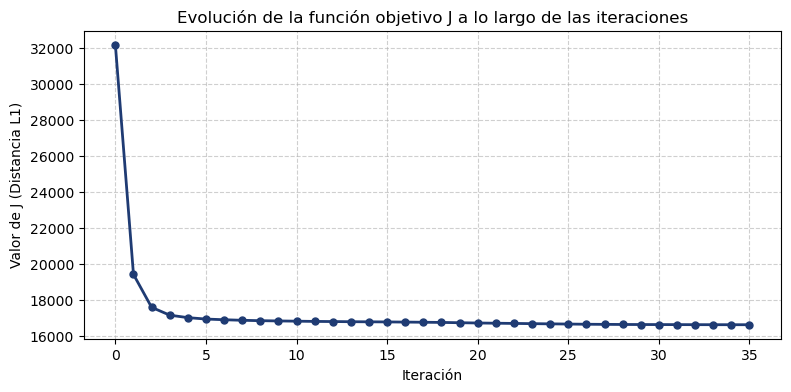

In [6]:
# TODO (c)
modelo = MiVariante(n_clusters=6)
modelo.fit(X1)

# Comprobación de predict
predicciones = modelo.predict(X1)
coinciden_predict = np.array_equal(predicciones, modelo.labels_)
print(f"¿predict(X1) coincide exactamente con labels_?: {coinciden_predict}")

# Dibujar la evolución del objetivo
plt.figure(figsize=(9, 4))
plt.plot(modelo.historial_j, marker='o', color='#1f3b73', lw=2, markersize=5)
plt.title("Evolución de la función objetivo J a lo largo de las iteraciones")
plt.xlabel("Iteración")
plt.ylabel("Valor de J (Distancia L1)")
plt.grid(True, ls="--", alpha=0.6)
plt.show()

In [7]:
# Datos de prueba exactos del ejemplo a mano
X_prueba = np.array([
    [0.1, 0.1, 0.1],
    [0.2, 0.2, 0.2],
    [0.8, 0.8, 0.8],
    [0.9, 0.9, 0.9]
])

# Ejecución de la variante
modelo_prueba = MiVariante(n_clusters=2, pesos=(1/3, 1/3, 1/3))
modelo_prueba.fit(X_prueba)

# Comprobaciones de las propiedades resueltas a mano
print("Etiquetas esperadas: [0 0 1 1]")
print(f"Etiquetas obtenidas: {modelo_prueba.labels_}")

print("\nCentros esperados: \n[[0.15 0.15 0.15]\n [0.85 0.85 0.85]]")
print(f"Centros obtenidos: \n{modelo_prueba.cluster_centers_}")

print("\nValor de J esperado: 0.2")
print(f"Valor de J obtenido (último de historial): {modelo_prueba.historial_j[-1]:.2f}")

assert np.array_equal(modelo_prueba.labels_, [0, 0, 1, 1]), "Las etiquetas no coinciden."
assert np.allclose(modelo_prueba.cluster_centers_, [[0.15, 0.15, 0.15], [0.85, 0.85, 0.85]]), "Los centros no coinciden."
assert np.isclose(modelo_prueba.historial_j[-1], 0.2), "El valor objetivo J no coincide."
print("\n¡El cálculo a mano coincide exactamente con la implementación!")

Etiquetas esperadas: [0 0 1 1]
Etiquetas obtenidas: [0 0 1 1]

Centros esperados: 
[[0.15 0.15 0.15]
 [0.85 0.85 0.85]]
Centros obtenidos: 
[[0.15 0.15 0.15]
 [0.85 0.85 0.85]]

Valor de J esperado: 0.2
Valor de J obtenido (último de historial): 0.20

¡El cálculo a mano coincide exactamente con la implementación!


### 1(d) — la paleta de tres cuadros, con vuestra variante y con `KMeans`

**TODO.** Para cada cuadro de `CUADROS_EJ1` y para $K \in \{3, 6, 12\}$, ajustad **vuestra
variante** sobre todos los píxeles, sustituid cada píxel por el centro (o representante) de su
grupo y mostrad el original y las tres versiones con su paleta debajo (`mostrar_paleta`). Ajustad
también `KMeans(n_clusters=K, n_init=1, random_state=SEED)` y comparad en una tabla el objetivo
$J$ de los dos y el tiempo de ajuste. Responded a las preguntas del enunciado.

In [8]:
K_PALETA = [3, 6, 12]
CUADROS_EJ1 
fila = cuadros.set_index("row_id").loc[CUADROS_EJ1[0]]
img1_original = cargar_imagen(fila["fichero"])
X1 = a_pixeles(img1_original) #Pixeles cuadro 1
fila2 = cuadros.set_index("row_id").loc[CUADROS_EJ1[1]]
img2_original = cargar_imagen(fila2["fichero"])
X2 = a_pixeles(img2_original) #Pixeles cuadro 2
fila3 = cuadros.set_index("row_id").loc[CUADROS_EJ1[2]]
img3_original = cargar_imagen(fila3["fichero"])
X3 = a_pixeles(img3_original) #Pixeles cuadro 3
#Modelo para el cuadro 1 con los diferentes k
lista_modelos_cuadro1 = []
lista_modelos_cuadro2 = []
lista_modelos_cuadro3 = []
for k in K_PALETA:
    modelo1 = MiVariante(n_clusters=k)
    modelo1.fit(X1)
    lista_modelos_cuadro1.append(modelo1)
    modelo2 = MiVariante(n_clusters=k)
    modelo2.fit(X2)
    lista_modelos_cuadro2.append(modelo2)
    modelo3 = MiVariante(n_clusters=k)
    modelo3.fit(X3)
    lista_modelos_cuadro3.append(modelo3)

Sustituir cada pixel por el centroide de su respectivo grupo.
En labels sustituyes cada pixel por el grupo al que pertenece, y te da un array donde en vez de aparecer 
píxeles aparecen los grupos a los que pertenecen. Tras eso, en X1_sustituido, sustituyes cada grupo 
por el centroide correspondiente, y te da un array donde en vez de aparecer los grupos aparecen los centroides.

In [9]:
X1
print(lista_modelos_cuadro1[0].cluster_centers_)
lista_modelos_cuadro1[0].labels_
X1_sustituido = lista_modelos_cuadro1[0].cluster_centers_[lista_modelos_cuadro1[0].labels_] 

[[0.86666667 0.74901961 0.64313725]
 [0.22745098 0.22352941 0.21960784]
 [0.7254902  0.36470588 0.23921569]]


Visualizar imagen original y versiones K = 3, K = 6 y K = 12.

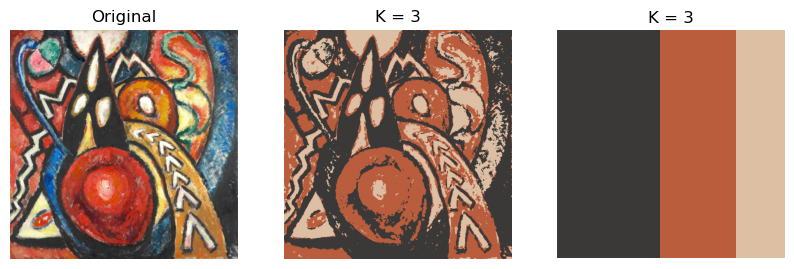

In [10]:




#Para una imagen individual
ModeloK3 = lista_modelos_cuadro1[0]
RecoloreadoK3 = ModeloK3.cluster_centers_[ModeloK3.labels_].reshape(img1_original.shape)

fig, axs = plt.subplots(1, 3, figsize=(10, 5))
axs[0].imshow(img1_original);        axs[0].set_title("Original"); axs[0].axis("off")
axs[1].imshow(RecoloreadoK3); axs[1].set_title("K = 3");    axs[1].axis("off")
axs[2].imshow(RecoloreadoK3); axs[2].set_title("K = 3");    axs[2].axis("off")
mostrar_paleta(axs[2], ModeloK3.cluster_centers_, np.bincount(ModeloK3.labels_))
plt.show()



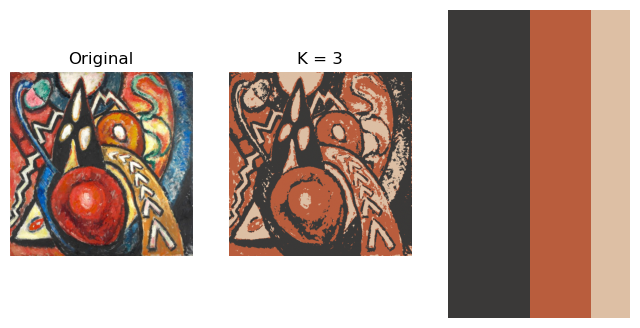

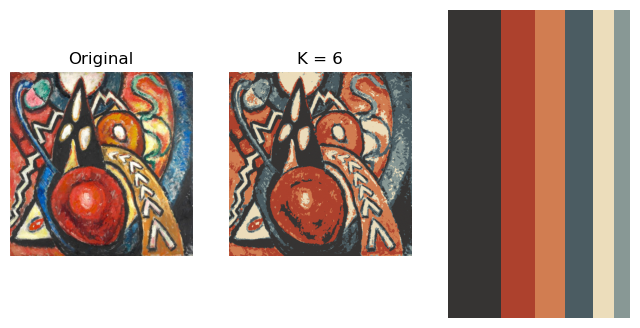

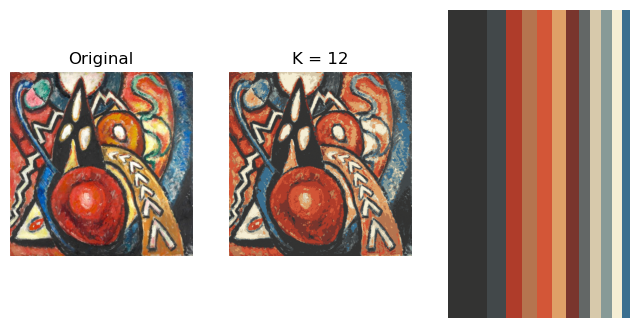

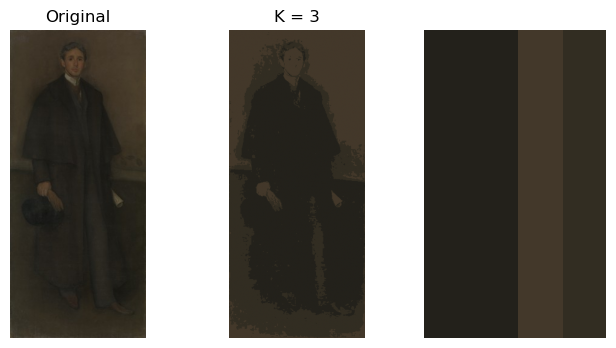

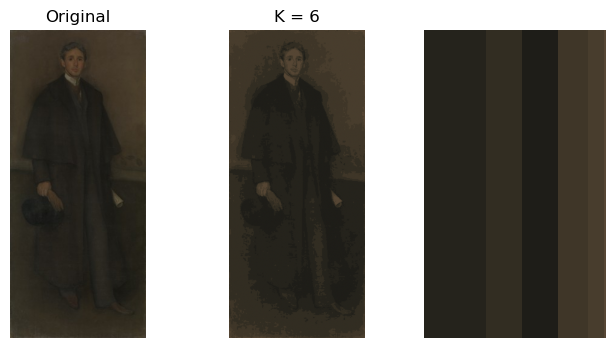

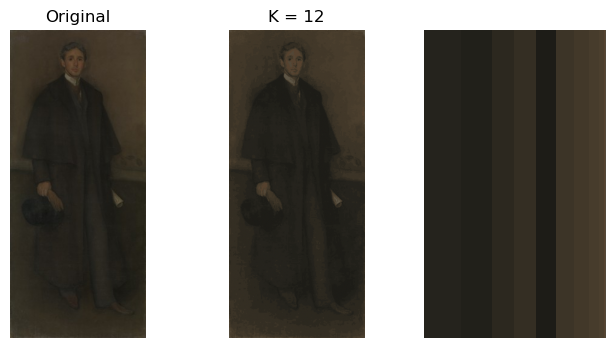

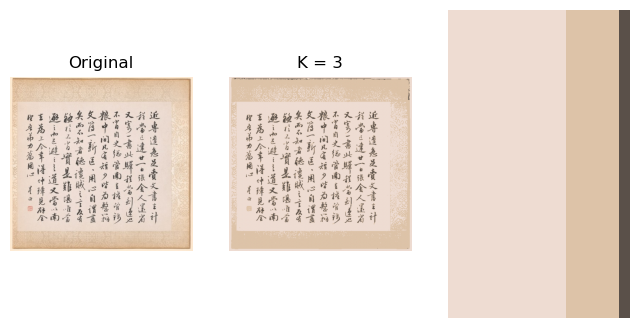

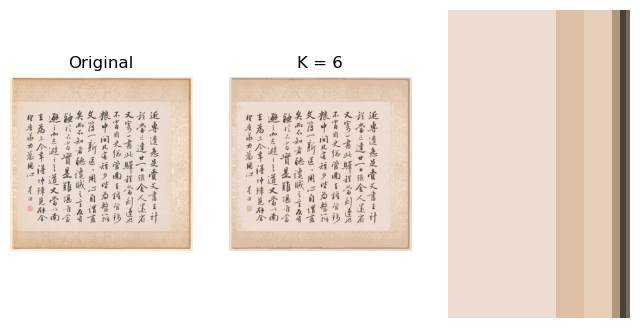

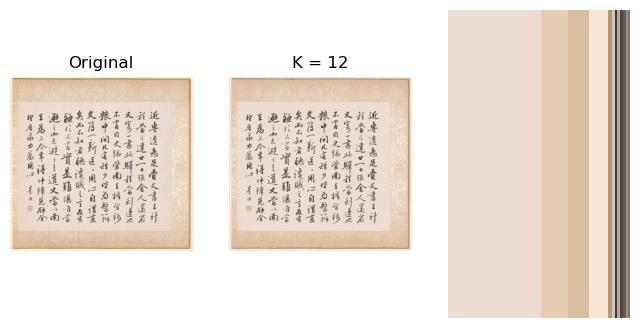

In [11]:
#Para cada cuadro, y para cada k. 

for lista_modelo in [[lista_modelos_cuadro1,img1_original],[lista_modelos_cuadro2,img2_original],[lista_modelos_cuadro3,img3_original]]:
    for k, modelo in zip(K_PALETA, lista_modelo[0]):
       recoloreado = modelo.cluster_centers_[modelo.labels_].reshape(lista_modelo[1].shape)
       fig, axs = plt.subplots(1, 3, figsize=(8, 4))
       axs[0].imshow(lista_modelo[1]); axs[0].set_title("Original"); axs[0].axis("off")
       axs[1].imshow(recoloreado); axs[1].set_title(f"K = {k}"); axs[1].axis("off")
       mostrar_paleta(axs[2], modelo.cluster_centers_, np.bincount(modelo.labels_))
       plt.show()



### 1(d) — lectura

**TODO.** Responded a las preguntas del enunciado: qué se conserva y qué se pierde al bajar $K$;
por qué los colores de la paleta parecen más apagados; qué les pasa a los colores llamativos de poca
superficie; y qué hace **vuestra** variante distinto de `KMeans`, con los números de la tabla.

---
## Ejercicio 2 — De cuadros a vectores: un diccionario común de colores (1.5)

Para agrupar **cuadros** hace falta describir cada uno con el mismo vector. Aquí $K_{\mathrm{dic}}$
es el tamaño del diccionario, fijado por el curso en `K_DIC = 24`. El diccionario se construye con
`sklearn.cluster.KMeans`.

### 2(a) — por qué no se comparan paletas directamente

No podemos comparar directamente las paletas de colores de los distintos cuadros posición por posición, porque cada algoritmo de agrupamiento obtiene los colores de forma independiente y asigna los índices de los clústeres sin seguir un orden común. Por ejemplo, el color de la posición 0 puede ser azul en un cuadro, amarillo en otro y rojo en un tercero. Esto hace que no podamos relacionar directamente los colores de una misma posición entre imágenes. Por eso, es necesario utilizar un espacio de colores común para todos los cuadros (diccionario compartido de colores).

### 2(b) — el diccionario

**TODO.** Tomad `PIX_POR_CUADRO` píxeles de cada cuadro, sin reemplazo, con un único
`rng = np.random.default_rng(SEED)` y recorriendo los cuadros en el orden de `cuadros.csv`.
Ajustad `KMeans(n_clusters=K_DIC, n_init=1, random_state=SEED)` sobre todos ellos juntos y
mostrad los 24 colores del diccionario.

c:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\maria\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\maria\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

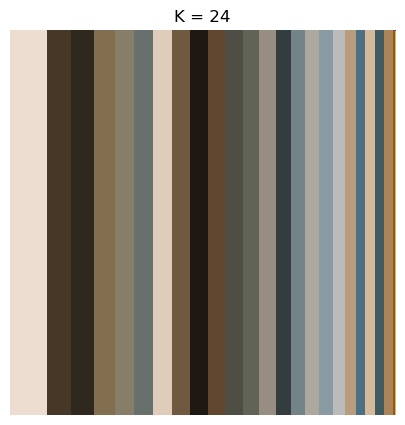

In [12]:
imagenes = [cargar_imagen(f) for f in cuadros["fichero"]]
pixeles = [a_pixeles(im) for im in imagenes]

rng = np.random.default_rng(SEED)
lista_pixeles_por_cuadro = []
for pix in pixeles:
    pixeles_elegidos = rng.choice(pix, size = PIX_POR_CUADRO, replace = False)
    lista_pixeles_por_cuadro.append(pixeles_elegidos)

modelo_KMeans = KMeans(n_clusters=K_DIC,n_init=1, random_state=SEED)
# vstack junta todos los arrays de pixeles de cada cuadro en un solo array grande, que es lo que se usa para pasar al modelo KMeans, como si fuera un solo conjunto de pixeles de un cuadro.
X_pixeles = np.vstack(lista_pixeles_por_cuadro)
modelo_KMeans.fit(X_pixeles)
colores_diccionario = modelo_KMeans.cluster_centers_

fig, axs = plt.subplots(1, 1, figsize=(10, 5))
axs.imshow(colores_diccionario); axs.set_title("K = 24");    axs.axis("off")
mostrar_paleta(axs, colores_diccionario, np.bincount(modelo_KMeans.labels_))
plt.show()


Se seleccionan aleatoriamente 2.000 píxeles de cada cuadro, sin repetir ninguno, utilizando el generador de números aleatorios con la primera semilla (SEED). Después, se reúnen todos los píxeles seleccionados en una única matriz (X_pixeles) y se aplica sobre ella KMeans, configurado con 24 clústeres ($K_{dic} = 24$), una única inicialización (n_init = 1) y la misma semilla (SEED). Finalmente, los centros obtenidos (cluster_centers_) forman un diccionario de 24 colores representativos que se utilizará para describir todos los cuadros de la colección de manera uniforme.

### 2(c) — la tabla de histogramas

**TODO.** Asignad **todos** los píxeles de cada cuadro al color más cercano del diccionario y
construid la tabla `H` ($n \times K_{\mathrm{dic}}$) con la proporción de cada color en cada cuadro.
Comprobad que cada fila suma 1 y mostrad, para dos cuadros que elijáis, su fila de `H` como un
diagrama de barras con los colores del diccionario.

Todo correcto, :)


Text(0.5, 0, 'Proporción de color')

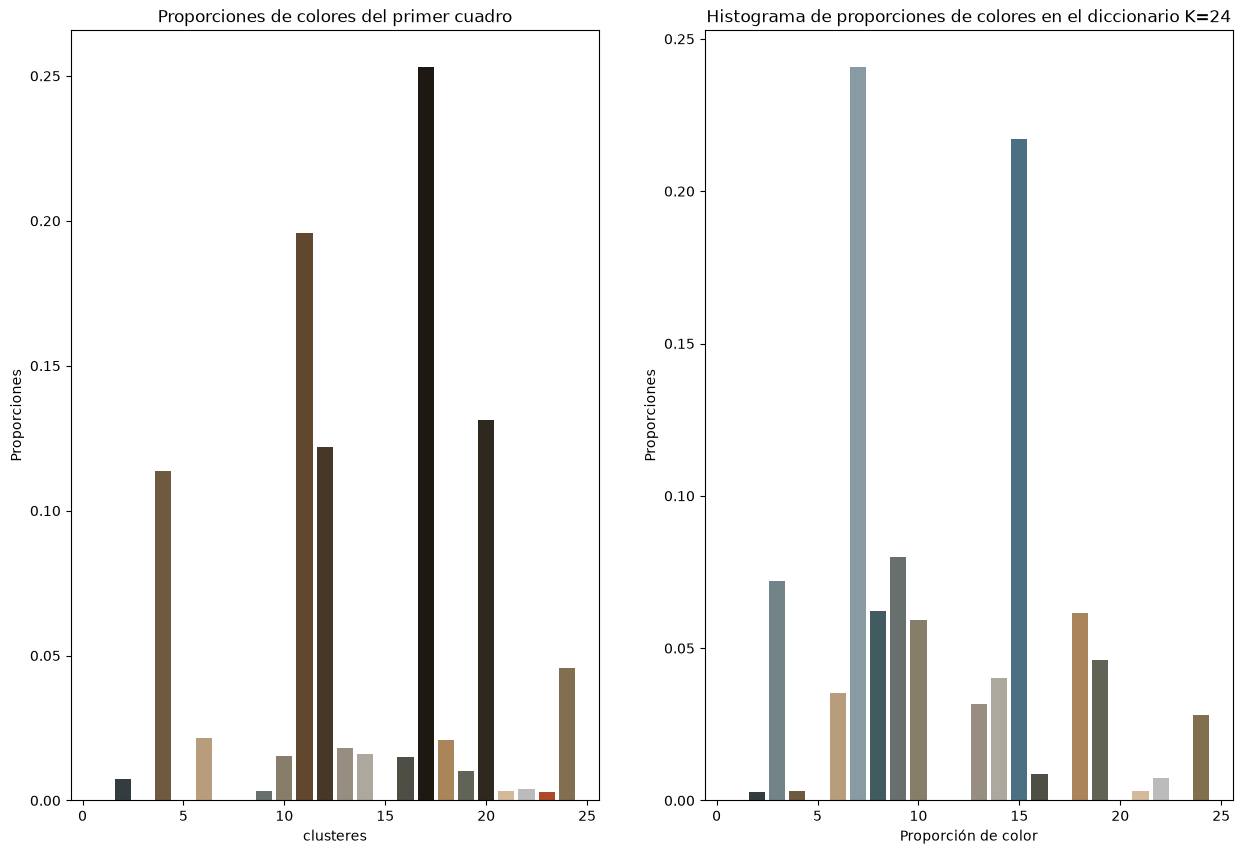

In [ ]:

# distancias = np.zeros((X_pixeles.shape[0], modelo_KMeans.n_clusters))
          
# for r in range(modelo_KMeans.n_clusters):
#     distancias[:, r] = np.sqrt(np.abs(X_pixeles[:, 0] - modelo_KMeans.cluster_centers_[r, 0]) ** 2 + np.abs(X_pixeles[:, 1] - modelo_KMeans.cluster_centers_[r, 1]) ** 2 + np.abs(X_pixeles[:, 2] - modelo_KMeans.cluster_centers_[r, 2]) ** 2)

# labels = np.argmin(distancias, axis=1)
# labels

#proporciones = np.bincount(labels)/np.sum(np.bincount(labels))

#H = n * proporciones, donde n es el número de pixeles en total, y proporciones es la proporción de cada color en el diccionario.
#H = X_pixeles.shape[0] * proporciones
proporciones = []
for pix in pixeles:
    labels = modelo_KMeans.predict(pix)
    proporciones.append(np.bincount(labels,minlength=K_DIC)/np.sum(np.bincount(labels,minlength=K_DIC)))
#print(proporciones)
#Hay que transformar la lista de proporciones en un array de numpy, para poder usarlo en un DataFrame de pandas. 

H = np.array(proporciones)   
                               
H_df = pd.DataFrame(H, index=cuadros["row_id"], columns=[f"Color_K_{i+1}" for i in range(K_DIC)])
for i in range(len(H_df)):
    suma = np.sum(H_df.iloc[i])
    if not np.isclose(suma, 1.0):
        raise ValueError(f"Hay un error en la suma de las proporciones para algun cuadro")
print(f"Todo correcto, :)")    
#print(H)
H_df
fig, axs = plt.subplots(1, 2, figsize=(15, 10))
axs[0].bar(range(1,25),H_df.iloc[0], color = modelo_KMeans.cluster_centers_)
axs[1].bar(range(1,25),H_df.iloc[1], color = modelo_KMeans.cluster_centers_)
axs[0].set_title("Proporciones de colores del primer cuadro")
axs[1].set_title("Proporciones de colores del segundo cuadro")
axs[0].set_xlabel("clusteres")
axs[1].set_xlabel("clusteres")
axs[0].set_ylabel("Proporciones")
axs[1].set_ylabel("Proporciones")



Asignamos cada píxel de los cuadros al centro más cercano del diccionario mediante modelo_KMeans.predict(pix). Después, calculamos la proporción de píxeles que corresponde a cada color utilizando np.bincount y minlength=K_DIC, para asegurarnos de que se tienen en cuenta todos los colores del diccionario. Con estos valores construimos la matriz $H$, de dimensiones $n \times K_{dic}$, y comprobamos con np.isclose que la suma de cada fila sea igual a $1.0$. Por último, mostramos las proporciones de color de dos cuadros mediante diagramas de barras, utilizando en cada barra el color correspondiente del diccionario.

### 2(d) — qué describe `H`, y la decisión de escala

**TODO.** ¿Qué describe una fila de `H` y qué ignora? ¿Vais a escalar `H` antes de agrupar?
Declarad la decisión, nombradla y argumentadla: las dos respuestas son defendibles, pero solo una
declarada y argumentada puntúa.

Cada fila de la matriz $H$ indica qué proporción del cuadro corresponde a cada uno de los 24 colores del diccionario común. Sin embargo, esta representación no tiene en cuenta dónde aparecen esos colores dentro de la imagen ni cómo están distribuidos. Es decir, se pierde toda la información espacial, como las formas, los contornos o la posición de los píxeles. De esta forma, cada cuadro queda representado únicamente por la frecuencia con la que aparece cada color.

#### Escala
**Declaración:** No aplicamos ningún escalado.

**Denominación:** Mantener las proporciones originales, sin estandarización ni normalización adicional.

**Argumentación:** La matriz $H$ ya contiene valores normalizados, ya que cada fila suma 1 y todos sus valores están comprendidos entre 0 y 1. Aunque al principio se planteó la posibilidad de escalar los datos por columnas, decidimos no hacerlo porque modificaría las frecuencias de cada color de forma independiente, alterando la relación original entre los colores de cada cuadro. Por tanto, mantenemos los valores originales, ya que aplicar un escalado adicional podría distorsionar las proporciones y cambiar la importancia relativa de los colores dominantes frente a los menos frecuentes.

---
## Ejercicio 3 — $K$-means y vuestra variante sobre los cuadros (2.0)

Aquí $K$ es el **número de grupos de cuadros**. La entrada es la tabla `H` del Ejercicio 2.
**El apartado (d) no está aquí**: necesita los metadatos y pertenece a la revelación.

### 3(a) — la rejilla

**TODO.** Para $K \in \{3, \dots, 8\}$: `KMeans` una vez con **cada** semilla de `P1_SEEDS` y
`n_init=1`, y **vuestra variante** (con las tres semillas si es aleatoria; una vez si es
determinista). Para cada ejecución: $J$, la silueta y los tamaños de grupo; para `KMeans`, además,
la **media** de $J$ en las tres semillas y su dispersión.

In [24]:
from sklearn.metrics import silhouette_score
MODELOS = []
K_GRID = list(range(3, 9))
for k in K_GRID:
    js_modelos = []
    silueta_modelos =[]
    silueta_modelos_l1 =[]
    tamanos_kmeans_modelos = []
    for semilla in P1_SEEDS: 
        modelo_kmeans1 = KMeans(n_clusters=k,n_init = 1,random_state = semilla) 
        modelo_kmeans1.fit(H)
        labels = modelo_kmeans1.predict(H)
        js_modelos.append(modelo_kmeans1.inertia_)
        silueta_modelos.append(silhouette_score(H, labels))
        silueta_modelos_l1.append(silhouette_score(H, labels,metric='manhattan'))
        tamanos_kmeans_modelos.append(np.bincount(labels).tolist())
    media_J_modelos = np.mean(js_modelos)
    std_J_modelos = np.std(js_modelos)
    js_modelos_personal = []
    silueta_modelos_personal =[]
    tamanos_kmeans_modelos_personal = []
    modelo_personal = MiVariante(n_clusters = k)
    modelo_personal.fit(H)
    labels = modelo_personal.predict(H)
    js_modelos_personal.append(modelo_personal.inertia_)
    silueta_modelos_personal.append(silhouette_score(H,labels)) 
    silueta_modelos_personal.append(silhouette_score(H,labels,metric='manhattan'))
    tamanos_kmeans_modelos_personal.append(np.bincount(labels).tolist())
    MODELOS.append({
        "K": k,
        "KMeans: J (Media)": media_J_modelos,
        "KMeans: J (Dispersión)": std_J_modelos,
        "KM s=13: J": js_modelos[0],
        "KM s=13: Silueta": silueta_modelos[0],
        "KM s=13: Silueta (l1)": silueta_modelos_l1[0],
        "KM s=13: Tamaños": str(tamanos_kmeans_modelos[0]),
        "KM s=41: J": js_modelos[1],
        "KM s=41: Silueta": silueta_modelos[1],
        "KM s=41: Silueta (l1)": silueta_modelos_l1[1],
        "KM s=41: Tamaños": str(tamanos_kmeans_modelos[1]),
        "KM s=97: J": js_modelos[2],
        "KM s=97: Silueta": silueta_modelos[2],
        "KM s=97: Silueta (l1)": silueta_modelos_l1[2],
        "KM s=97: Tamaños": str(tamanos_kmeans_modelos[2]),
        "MiVariante: J": js_modelos_personal[0],
        "MiVariante: Silueta (euclid)": silueta_modelos_personal[0],
        "MiVariante: Silueta (L1)": silueta_modelos_personal[1],      
        "MiVariante: Tamaños": str(tamanos_kmeans_modelos_personal[0])}
    )
MODELOS

Resultado_df = pd.DataFrame(MODELOS)
Resultado_df.set_index("K")

    

        


,KMeans: J (Media),KMeans: J (Dispersión),KM s=13: J,KM s=13: Silueta,KM s=13: Silueta (l1),KM s=13: Tamaños,KM s=41: J,KM s=41: Silueta,KM s=41: Silueta (l1),KM s=41: Tamaños,KM s=97: J,KM s=97: Silueta,KM s=97: Silueta (l1),KM s=97: Tamaños,MiVariante: J,MiVariante: Silueta (euclid),MiVariante: Silueta (L1),MiVariante: Tamaños
K,,,,,,,,,,,,,,,,,,
3,4.653886,0.000000,4.653886,0.318483,0.338051,"[10, 32, 14]",4.653886,0.318483,0.338051,"[32, 10, 14]",4.653886,0.318483,0.338051,"[32, 10, 14]",1.585948,0.306224,0.335331,"[10, 16, 30]"
4,4.297340,0.218187,4.178511,0.297032,0.295953,"[10, 32, 8, 6]",4.110140,0.289958,0.300174,"[31, 10, 10, 5]",4.603367,0.198799,0.210097,"[4, 10, 35, 7]",1.495355,0.231172,0.276252,"[10, 15, 17, 14]"
5,4.033239,0.155644,4.011136,0.282812,0.252551,"[3, 32, 8, 6, 7]",3.854629,0.276493,0.271491,"[31, 10, 9, 5, 1]",4.233951,0.207403,0.206328,"[4, 10, 34, 7, 1]",1.425193,0.237320,0.274805,"[10, 13, 11, 5, 17]"
6,3.548504,0.028444,3.541498,0.288614,0.243919,"[3, 28, 7, 6, 7, 5]",3.586311,0.235299,0.236984,"[17, 10, 9, 5, 1, 14]",3.517704,0.245646,0.254674,"[4, 10, 27, 7, 1, 7]",1.376443,0.229889,0.272065,"[10, 13, 10, 5, 16, 2]"
7,3.197561,0.062766,3.187297,0.299181,0.252510,"[3, 27, 7, 6, 7, 5, 1]",3.279050,0.257748,0.250190,"[17, 10, 9, 3, 1, 14, 2]",3.126336,0.271421,0.255907,"[4, 10, 25, 7, 1, 7, 2]",1.373744,0.218195,0.264729,"[10, 12, 3, 5, 13, 2, 11]"
8,2.852192,0.045432,2.891340,0.254554,0.236072,"[3, 18, 9, 7, 5, 9, 1, 4]",2.788496,0.324905,0.267196,"[27, 10, 9, 1, 2, 1, 3, 3]",2.876740,0.263177,0.251034,"[4, 10, 18, 6, 8, 2, 7, 1]",1.303543,0.243125,0.261613,"[10, 4, 3, 4, 13, 2, 12, 8]"


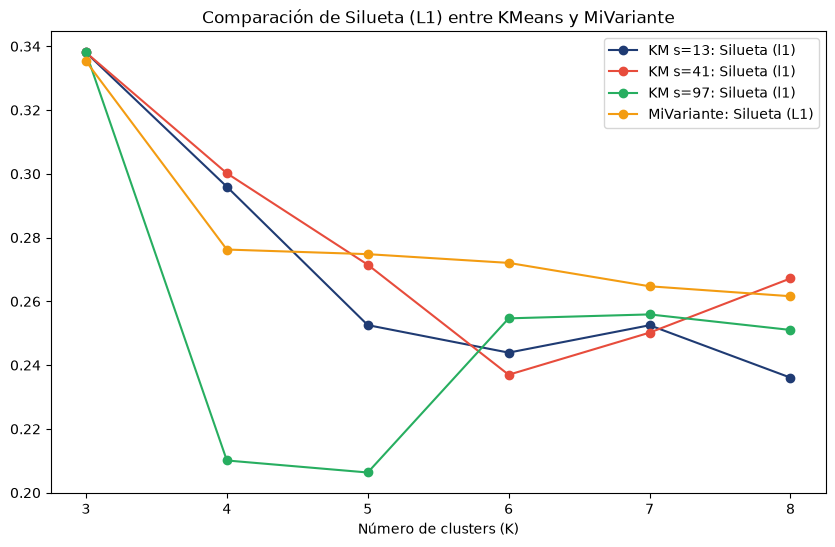

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
plt.plot(Resultado_df["K"], Resultado_df["KM s=13: Silueta (l1)"], marker='o', label='KM s=13: Silueta (l1)', color='#1f3b73')
plt.plot(Resultado_df["K"], Resultado_df["KM s=41: Silueta (l1)"], marker='o', label='KM s=41: Silueta (l1)', color='#e74c3c')
plt.plot(Resultado_df["K"], Resultado_df["KM s=97: Silueta (l1)"], marker='o', label='KM s=97: Silueta (l1)', color='#27ae60')
plt.plot(Resultado_df["K"], Resultado_df["MiVariante: Silueta (L1)"], marker='o', label='MiVariante: Silueta (L1)', color='#f39c12')
plt.title("Comparación de Silueta (L1) entre KMeans y MiVariante")
plt.xlabel("Número de clusters (K)")
ax.legend()

### 3(a) — lectura

**TODO.** ¿Qué muestra la tabla? ¿Por qué informar del **mejor** de los tres reinicios de `KMeans`
hablaría de vuestra inicialización más afortunada y no de $K$? ¿Cómo se compara vuestra variante?

### Antes de congelar: las reglas

Tres preguntas distintas, que no deben mezclarse:

1. **¿Qué $K$?** A partir de la evidencia **no supervisada**. $J$ baja con $K$ por construcción, así
   que «$J$ es mínimo en $K = 8$» no es un argumento.
2. **¿Qué algoritmo?** `KMeans` o vuestra variante, con una regla no supervisada declarada.
3. **¿Qué ejecución?** Solo **después** de fijar $K$ y algoritmo, si hay varias (por ejemplo, la de
   menor $J$ **con el $K$ ya fijado**).

**TODO — escribid aquí las reglas**, y aplicadlas en la celda siguiente.

Vamos a basarnos para tomar el mejor k en función del valor de la silueta. En nuestro caso,
todos los modelos vemos que tienen mejor silueta para k=3, y a partir de ahi va reduciendose.
Por lo que tomamos k = 3. 
K_REF = 3.
Viendo que para k=3 nuestro modelo tiene mejor silueta con distancia L1, asi que 
nos quedaríamos con nuestra variante. 0.335331


In [26]:
# TODO (b) Aplicad las reglas: fijad K, el algoritmo y UNA partición. Guardad sus etiquetas:
#          la rejilla de miniaturas y la revelación deben usarla a ella.

K_REF = 4
ALGORITMO_REF = MiVariante(n_clusters=K_REF)

SEMILLA_REF = None

ALGORITMO_REF.fit(H)
grupos_km = ALGORITMO_REF.labels_
grupos_km

array([1, 2, 1, 0, 3, 0, 2, 3, 1, 0, 1, 3, 0, 2, 2, 2, 2, 3, 3, 1, 2, 0,
       0, 1, 2, 2, 1, 3, 2, 3, 3, 1, 2, 1, 1, 2, 2, 1, 3, 0, 0, 3, 3, 0,
       3, 2, 2, 1, 3, 1, 2, 1, 0, 3, 1, 2])

### 3(b) — los grupos, vistos

**TODO.** Mostrad la rejilla de miniaturas de vuestra partición con `rejilla_miniaturas` y
describid cada grupo **en términos de color y de luz**: todavía no sabéis quién pintó cada cuadro,
y vuestro argumento no puede apoyarse en reconocerlo.

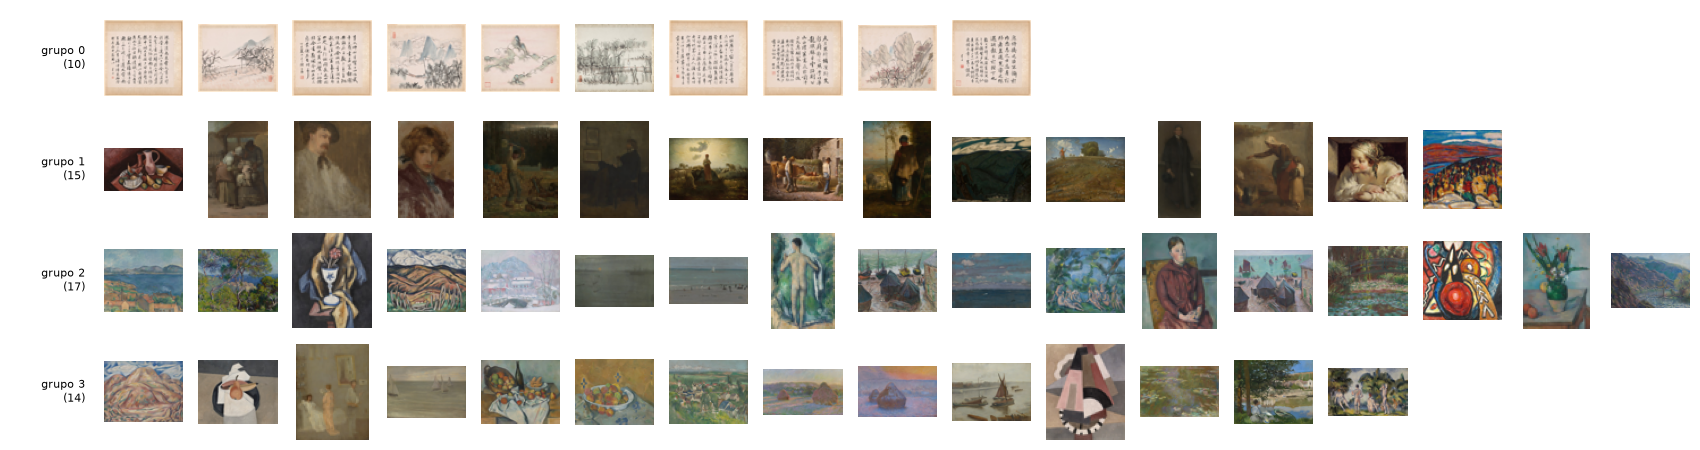

In [27]:
# TODO (b) 
rejilla_miniaturas(cuadros["fichero"], grupos_km)

Los cuadros se muestran con la funcion auxiliar proporcionada, al mostrar estas rejillas comprobamos que hay tres grupos que aparentemente están muy diferenciados. En primera fila unos cuadros de colores simples y muy claros. En segunda fila unos cuadros de colores oscuros y tonalidades con menos luminosidad y con una mayor cantidad de colores usados respecto al primero. Una tercera fila con unos cuadros con un uso diverso de colores, pero con una mayor luminosidad y colores de fondo claros o colores más llamativos, aunque cabe destacar que al ser un grupo más amplio agrupa cuadros que son bastante más heterogéneos en cuanto a colores en comparación a los otros clusters, pero guardan relacion de luz vibrante. El último grupo finalmente, muestra una aparente mezcla de contraste entre el segundo grupo y el tercero, ya que es una conbinaciones de muchos colores pero en una luminosidad más neutra con cuadros que parecen tender un poco más al claro y otros que parecen tender más al oscuro sin llegar a esos extremos.

## DECISIÓN CONGELADA — K-MEANS

**TODO — 3(c). Este encabezado es uno de los dos que comprueba el sello. No lo cambiéis.**

Rellenadlo **antes** que nada de lo que sigue y antes de que ninguna celda lea los metadatos. Lo
que se congela es **una** partición.

| Campo | Valor |
|---|---|
| $K$ | *4* |
| Algoritmo (`KMeans` o vuestra variante) | *nuestra variante (K-medianas ℓ1 con inicialización por máxima separación, pesos uniformes)* |
| Semilla, si procede | *sin semilla porque es determinista* |
| Escalado de `H` | *H sin escalar* |
| Reglas que eligieron $K$, algoritmo y ejecución | *Elección de K: Codo de la curva de la silueta-K y por homogeneidad de grupos. Algoritmo: Desempate. Ejecución: Única (algoritmo determinista)* |

**Argumento no supervisado.** 

*Las limitaciones:*

- *La elección de algoritmo se decide en el desempate, no por una diferencia de calidad, la diferencia entre siluetas es similiar de manera que podemos argumentar empate por lo que el siguiente criterio que comparamos sería cuál es la más equilibrada, el primer caso de KMeans agrupa por ejmplo en la semilla 97 [4, 10, 35, 7], nuestra variante por [10, 15, 17, 14], por lo que nuestra variante es ligeramente más equilibrada puesto que no genera un grupo demasiado grande ni demasiado pequeño, sin embargo consideramos una diferencia de que aparentemente no es tan clas y por tanto pasamos a un criterio de desempate. En este caso el criterio final es decantarnos por la naturaleza determinista de nuestro algoritmo ya que KMeans puede empeorar con otras semillas.*

- *Se generan algunos grupos que aparentemente mezclan cuadros "outliers" puesto que hay cuadros que usan más colores, aunque mantengan una luminosidad similar a la del grupo asignado*

- *Hemos escogido K = 4 que realmente no tiene la mejor silueta, sin embargo, nosotros estabamos debatiendo, ya que pensabamos que es posible que tener grupos demasiado grandes o pequeños nos indicaría un agrupamiento no tan favorable, y por tanto búscabamos grupos más homogeneos y de tamaños más similares. Sin embargo hemos revisado que no necesariamente grupos más homogeneos deban ser mejores, puesto que si hay mucha cantidad de cuadros parecidos lo normal es que también haya un grupo grande de cuadros parecidos.* 

In [28]:
# Congelad la tabla anterior en código, para que nada de lo que sigue pueda apartarse de ella.
CONGELADO_KMEANS = dict(K=K_REF, algoritmo=ALGORITMO_REF, semilla=SEMILLA_REF)
print("CONGELADO_KMEANS:", CONGELADO_KMEANS)

CONGELADO_KMEANS: {'K': 4, 'algoritmo': MiVariante(n_clusters=4,
           pesos=array([0.04166667, 0.04166667, 0.04166667, 0.04166667, 0.04166667,
       0.04166667, 0.04166667, 0.04166667, 0.04166667, 0.04166667,
       0.04166667, 0.04166667, 0.04166667, 0.04166667, 0.04166667,
       0.04166667, 0.04166667, 0.04166667, 0.04166667, 0.04166667,
       0.04166667, 0.04166667, 0.04166667, 0.04166667])), 'semilla': None}


---
## Ejercicio 4 — Agrupamiento jerárquico de los cuadros (2.0)

La misma tabla `H` y el mismo sello: **los apartados (a) a (c) no usan metadatos**. Aquí $K$ es
también el número de grupos.

### 4(a) — los cuatro enlaces

**TODO.** Agrupamiento aglomerativo con `ward`, `complete`, `average` y `single`. Indicad la
restricción de métrica de `ward` y mostrad qué ocurre si se le pide otra.

In [29]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage as scipy_linkage

ENLACES = ["ward", "complete", "average", "single"]
modelos = {}
for enlace in ENLACES:  
    modelo = AgglomerativeClustering(n_clusters=4,metric = 'euclidean',linkage= enlace)
    modelo.fit_predict(H)
    modelos[enlace] = modelo

#Otra metrica 
modelo = AgglomerativeClustering(n_clusters=4,metric = 'l1',linkage= 'ward')

   
#Sale en rojo metric y n_cluster y pone not fitted.
modelo


,n_clusters,4
,metric,'l1'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


### 4(b) — dos criterios, declarados antes de aplicarlos

1. **Dentro de cada enlace, ¿qué $K$?** Cada enlace es una jerarquía distinta: **cada enlace
   tiene su propio $K$**.
2. **Entre enlaces, ¿cuál preferís?** Una regla que pueda elegir uno, solo con evidencia no
   supervisada. «El que se ve mejor» no es una regla.

**TODO — escribid aquí las dos reglas** y aplicadlas en la celda siguiente.

In [30]:
# TODO (b) Regla 1 en CADA enlace -> elegidos[enlace] = K. Regla 2 -> un enlace preferido.


modelos_aglomerativos = {}
Modelos_aglomerative = []
n = H.shape[0]  
Z_enlaces = {}


for enlace in ENLACES:                                          
    Z_enlaces[enlace] = scipy_linkage(H, method=enlace, metric='euclidean')



for k in range(3,9):
    silueta_modelos =[]
    tamanos_aglomerative_modelos = []
    salto_entre_enlace = []
    saltos_modelos = []                                         
    for enlace in ENLACES: 
        modelo_aglomerativo = AgglomerativeClustering(n_clusters=k,metric = 'euclidean',linkage= enlace)
        modelo_aglomerativo.fit_predict(H)
        modelos_aglomerativos[enlace] = modelo_aglomerativo
        modelo_actual = modelos_aglomerativos[enlace]
        silueta_modelos.append(silhouette_score(H, modelo_actual.labels_))
        tamanos_aglomerative_modelos.append(np.bincount(modelo_actual.labels_).tolist())
        # calcular alturas de fusión
        h = Z_enlaces[enlace][:, 2]                             
        saltos_modelos.append(h[n - k] / h[n - k - 1])
        

    Modelos_aglomerative.append({
        "K": k,
        "Aglomerative ward: Silueta": silueta_modelos[0],
        "Aglomerative ward: Tamaños": str(tamanos_aglomerative_modelos[0]),
        "Aglomerative ward: Salto": saltos_modelos[0], 
        "Aglomerative complete: Silueta": silueta_modelos[1],
        "Aglomerative complete: Tamaños": str(tamanos_aglomerative_modelos[1]),
        "Aglomerative complete: Salto": saltos_modelos[1],
        "Aglomerative average: Silueta": silueta_modelos[2],
        "Aglomerative average: Tamaños": str(tamanos_aglomerative_modelos[2]),
        "Aglomerative average: Salto": saltos_modelos[2],  
        "Aglomerative single: Silueta": silueta_modelos[3],
        "Aglomerative single: Tamaños": str(tamanos_aglomerative_modelos[3]),
        "Aglomerative single: Salto": saltos_modelos[3], 
       }
    )
Aglomerative_df = pd.DataFrame(Modelos_aglomerative).set_index('K')



elegidos = {"ward":3, "complete":5,"average":6, "single":4}
ENLACE_REF = "ward"

Aglomerative_df

,Aglomerative ward: Silueta,Aglomerative ward: Tamaños,Aglomerative ward: Salto,Aglomerative complete: Silueta,Aglomerative complete: Tamaños,Aglomerative complete: Salto,Aglomerative average: Silueta,Aglomerative average: Tamaños,Aglomerative average: Salto,Aglomerative single: Silueta,Aglomerative single: Tamaños,Aglomerative single: Salto
K,,,,,,,,,,,,
3,0.309986,"[16, 10, 30]",1.364895,0.357678,"[40, 11, 5]",1.075454,0.388524,"[45, 1, 10]",1.035695,0.214182,"[54, 1, 1]",1.066368
4,0.308843,"[8, 8, 30, 10]",1.306515,0.336032,"[11, 38, 5, 2]",1.038361,0.360550,"[44, 1, 10, 1]",1.041733,0.360550,"[44, 10, 1, 1]",1.143241
5,0.312838,"[30, 8, 6, 10, 2]",1.024173,0.346412,"[5, 38, 10, 2, 1]",1.089822,0.343622,"[43, 1, 10, 1, 1]",1.065540,0.343622,"[43, 10, 1, 1, 1]",1.073598
6,0.317211,"[28, 8, 2, 10, 2, 6]",1.010437,0.348799,"[38, 2, 10, 3, 1, 2]",1.007775,0.331910,"[38, 1, 5, 1, 1, 10]",1.145367,0.287391,"[41, 10, 2, 1, 1, 1]",1.048825
7,0.325477,"[8, 27, 2, 10, 2, 6, 1]",1.034174,0.249548,"[2, 21, 17, 3, 1, 2, 10]",1.069939,0.312333,"[5, 1, 36, 1, 1, 10, 2]",1.030951,0.238199,"[40, 10, 2, 1, 1, 1, 1]",1.000481
8,0.350225,"[27, 10, 2, 5, 2, 6, 1, 3]",1.062333,0.250405,"[21, 3, 17, 1, 1, 2, 10, 1]",1.023085,0.317743,"[36, 2, 10, 1, 1, 3, 2, 1]",1.045795,0.225192,"[39, 10, 2, 1, 1, 1, 1, 1]",1.056957


La tabla con metricas nos sirve como criterio no supervisado como en el anterior ejercicio. En este caso mostramos como metrica principal el salto y pensamos en calcular las siluetas por si hubiera caso de empate tener un criterio medible de desempate. Finalmente nuestra decisión se basa en máximizar el salto al realizar el clustering aglomerativo. Por tanto la decisión de mayor salto nos fija el linkage ward con K = 3.

### 4(c) — un dendrograma

**TODO.** El dendrograma del enlace **preferido**, cortado en **su** $K$, con
`dendrograma_con_miniaturas`. Leedlo: ¿qué fusiones son tempranas y baratas, y cuál es tan cara
que vuestra regla cortó por debajo?

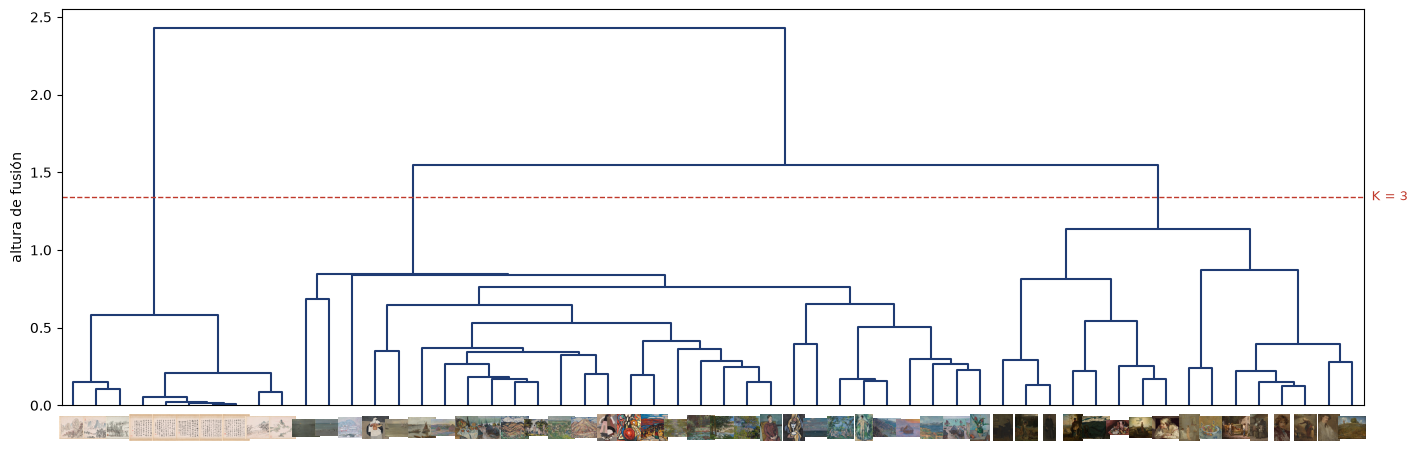

In [31]:
#(c) 
dendrograma_con_miniaturas(scipy_linkage(H, method=ENLACE_REF), cuadros["fichero"], K=elegidos[ENLACE_REF])

**TODO** EXPLICAR

## DECISIÓN CONGELADA — AGLOMERATIVO

**TODO. El segundo encabezado que comprueba el sello. No lo cambiéis.**

| Enlace | $K$ congelado | Por qué la regla 1 llegó ahí |
|---|---|---|
| `ward` | *3* | *Mayor salto del rango (1.365), K = 4 queda cerca (1.307), y los demás K no pasan de 1.06. Deja grupos de [16, 10, 30], todos con al menos 10 cuadros.* |
| `complete` | *5* | *Mayor salto (1.090), se encunetra entre K = 3 (1.075) y K = 7 (1.070), la jerarquía no tiene una frontera clara. K = 5 Deja [5, 38, 10, 2, 1], con un cuadro aislado.* |
| `average` | *6* | *Mayor salto (1.145), claramente por encima del siguiente (K = 5, 1.066). Pero la fusión que evita es la de grupos pequeños: K = 6 deja [38, 1, 5, 1, 1, 10], con tres cuadros sueltos.* |
| `single` | *4* | *Mayor salto (1.143), por delante claramente de K = 5 (1.074). K = 4 deja [44, 10, 1, 1], un grupo gigante y dos cuadros sueltos, parece seguir el patrón de encadenamiento.* |

**Enlace preferido (regla 2):** *Ward con K = 3, Según la regla 2, preferimos el enlace cuyo salto seleccionado en la regla 1 es mayor. El enlace ward supera y es un claro ganador en esta métrica (1.365). Además, aunque los tamaños no intervienen en la regla, `ward` es el único enlace cuyo corte da grupos con homegeneidad aparentemente mejor al resto, [16, 10, 30], puesto que evita cuadros aislados. Aúnque no necesariamente esa homogeneidad aplique mejores grupos, si que podemos ver el caso como el de single que parece un patrón de encadenamiento con un grupo con varios aislados y otro grupo muy grande*. 

In [32]:
CONGELADO_AGLO = dict(elegidos)       # enlace -> su K congelado
ENLACE_PREFERIDO = ENLACE_REF
print("CONGELADO_AGLO  :", CONGELADO_AGLO)
print("ENLACE_PREFERIDO:", ENLACE_PREFERIDO)

CONGELADO_AGLO  : {'ward': 3, 'complete': 5, 'average': 6, 'single': 4}
ENLACE_PREFERIDO: ward


In [33]:
# Creamos un diccionario para recolectar los datos
datos_tamaños = {}

for enlace in ENLACES:
    k_elegido = elegidos[enlace]
    columna_elegida = Aglomerative_df.loc[k_elegido, f'Aglomerative {enlace}: Tamaños']
    datos_tamaños[f'Aglomerative {enlace}: Tamaños'] = columna_elegida

# Si los valores extraídos son listas (ej: [10, 15, 20]), al crear el DataFrame 
# con orientación index, se pondrán en una sola fila.
tamaños_elegidos = pd.DataFrame([datos_tamaños])
tamaños_elegidos

,Aglomerative ward: Tamaños,Aglomerative complete: Tamaños,Aglomerative average: Tamaños,Aglomerative single: Tamaños
0,"[16, 10, 30]","[5, 38, 10, 2, 1]","[38, 1, 5, 1, 1, 10]","[44, 10, 1, 1]"


---
## REVELACIÓN — VALIDACIÓN EXTERNA

**Este es el primer punto en el que podéis tocar los metadatos.** Están en `Datos/metadatos.csv`:
autor, época, año, técnica, título y la referencia del museo. Se alinean por **`row_id`**.

Las dos configuraciones de arriba están congeladas y nada de lo que sigue puede cambiarlas.
Recalcular índices para varios $K$, semillas, algoritmos o enlaces y presentar el mejor es una
penalización automática.

In [34]:
# Se abre AQUÍ, dentro de la revelación, y en ningún sitio antes.
METADATOS_FILE = os.path.join(DATOS, "metadatos.csv")


def cargar_metadatos(cuadros, path=None):
    """metadatos.csv: row_id, autor, epoca, anio, tecnica, titulo, tecnica_original, aic_id.
    Se alinea por row_id con la tabla de cuadros, nunca por posición."""
    meta = pd.read_csv(path or METADATOS_FILE)
    m = cuadros[["row_id"]].merge(meta, on="row_id", how="left", validate="1:1")
    assert m["autor"].notna().all(), "hay un cuadro sin metadatos"
    assert (m["row_id"].to_numpy() == cuadros["row_id"].to_numpy()).all()
    return m

In [35]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

# TODO Cargad los metadatos por primera vez con cargar_metadatos(cuadros).
meta = cargar_metadatos(cuadros)
print(meta)
y_autor = meta['autor']
y_epoca = meta['epoca']

    row_id                   autor           epoca  anio  \
0        1         Marsden Hartley  1900 o después  1923   
1        2            Paul Cezanne       1875-1899  1880   
2        3    Jean François Millet       1850-1874  1857   
3        4                    Xugu       1875-1899  1897   
4        5         Marsden Hartley  1900 o después  1920   
5        6                    Xugu       1875-1899  1895   
6        7            Claude Monet       1875-1899  1884   
7        8         Marsden Hartley  1900 o después  1917   
8        9  James McNeill Whistler       1850-1874  1871   
9       10                    Xugu       1875-1899  1897   
10      11  James McNeill Whistler       1875-1899  1896   
11      12  James McNeill Whistler       1850-1874  1865   
12      13                    Xugu       1875-1899  1895   
13      14         Marsden Hartley  1900 o después  1917   
14      15         Marsden Hartley  1900 o después  1918   
15      16            Claude Monet      

### 3(d) — validación externa de la partición congelada

**TODO.** Índice de Rand ajustado (ARI) e información mutua ajustada (AMI) de la partición
congelada **frente al autor y frente a la época**, y la tabla de contingencia grupo × autor.
Volved a mostrar la rejilla de miniaturas, ahora con el autor de cada cuadro a la vista
(argumento `rotulos` de `rejilla_miniaturas`). Después, la pregunta de fondo: **¿qué ha agrupado
realmente el algoritmo?**

In [36]:
# TODO 3(d) solo para la partición CONGELADA
CONGELADO_KMEANS
ARI_autor = adjusted_rand_score(y_autor,CONGELADO_KMEANS['algoritmo'].labels_)
AMI_autor = adjusted_mutual_info_score(y_autor,CONGELADO_KMEANS['algoritmo'].labels_)

print(ARI_autor)
print(AMI_autor)

Tabla_cont_autor = pd.crosstab(index=CONGELADO_KMEANS['algoritmo'].labels_, columns=y_autor)
Tabla_cont_autor

0.2956918292412027
0.42901842126701845


autor,Claude Monet,James McNeill Whistler,Jean François Millet,Marsden Hartley,Paul Cezanne,Xugu
row_0,,,,,,
0,0,0,0,0,0,10
1,0,4,8,3,0,0
2,6,3,0,3,5,0
3,4,3,0,3,4,0


In [37]:
ARI_epoca = adjusted_rand_score(y_epoca,CONGELADO_KMEANS['algoritmo'].labels_)
AMI_epoca = adjusted_mutual_info_score(y_epoca,CONGELADO_KMEANS['algoritmo'].labels_)

print(ARI_epoca)
print(AMI_epoca)

Tabla_cont_epoca = pd.crosstab(index=CONGELADO_KMEANS['algoritmo'].labels_, columns=y_epoca)
Tabla_cont_epoca

0.13816899248581505
0.19713045406364707


epoca,1800-1849,1850-1874,1875-1899,1900 o después
row_0,,,,
0,0,0,10,0
1,2,8,2,3
2,0,1,12,4
3,0,6,4,4


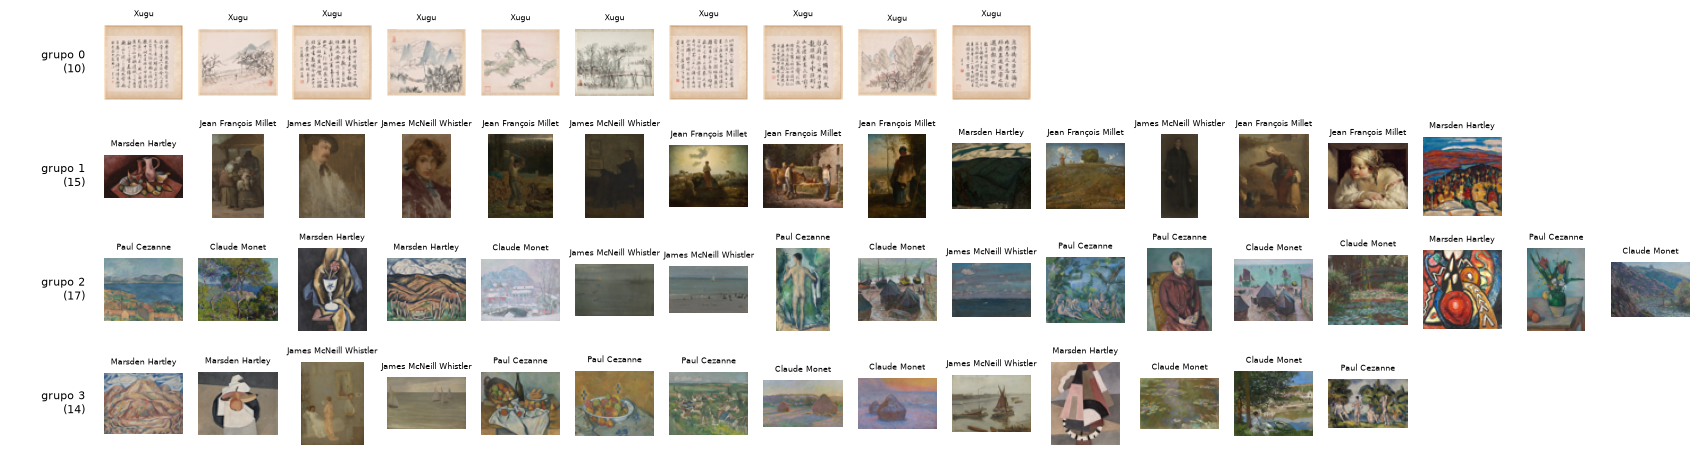

In [38]:
rejilla_miniaturas(cuadros["fichero"], CONGELADO_KMEANS['algoritmo'].labels_, rotulos=y_autor)

En conclusión vemos que el algoritmo no tiene en cuenta el autor ni la época para agrupar, sino que tuvo en cuenta los tonos de colores de los pixeles de cada cuadro.

### 4(d) — validación externa de cada enlace congelado

**TODO.** Los mismos índices para **cada** enlace con **su** $K$ congelado. Indicad el $K$ en cada
fila y marcad el enlace preferido. Después, la comparación: ¿coinciden el enlace con **mejor**
acuerdo con el autor y el que preferisteis **sin** metadatos? Si no coinciden, decidlo sin rodeos.

In [39]:
# TODO 4(d) 
Modelos_aglomerativos = []
for enlace in ENLACES:
    K = CONGELADO_AGLO[enlace]
    modelo_aglomerativo = AgglomerativeClustering(n_clusters=CONGELADO_AGLO[enlace], linkage=enlace) 
    Labels_congelado = modelo_aglomerativo.fit(H).labels_
    Modelos_aglomerativos.append({

        "Enlace": enlace + (" preferido" if enlace == ENLACE_REF else ""),
        "K": K,
        "ARI autor": adjusted_rand_score(y_autor, Labels_congelado),
        "AMI autor": adjusted_mutual_info_score(y_autor, Labels_congelado),
        "ARI época": adjusted_rand_score(y_epoca, Labels_congelado),
        "AMI época": adjusted_mutual_info_score(y_epoca, Labels_congelado),

    })

Validacion_df = pd.DataFrame(Modelos_aglomerativos).set_index("Enlace")
Validacion_df

,K,ARI autor,AMI autor,ARI época,AMI época
Enlace,,,,,
ward preferido,3,0.295886,0.489058,0.136300,0.235658
complete,5,0.163122,0.357023,-0.030390,0.091247
average,6,0.161046,0.341956,-0.029489,0.100739
single,4,0.142441,0.370294,-0.049862,0.130187


**TODO** Finalmente, comprobamos que justo coincidio el elegido con el mejor enlace en validación externa. La regla de escoger el que máximiza el salto nos permitió elegir correctamente el K y enlace que mejor desempeño ha tenido.

### 4(e) — comparación de los cuatro enlaces

**TODO.** Con los tamaños de grupo que registrasteis **antes** de la revelación, comparad lo que
hicieron los cuatro enlaces con estos datos y explicad cada uno a partir de lo que mide entre dos
grupos. Comprobad si `single` muestra **encadenamiento**; si no lo muestra, decidlo.

---
## Ejercicio 5 — PCA: el mapa de los cuadros (1.5)

PCA sobre la tabla `H`, centrada y **con la misma decisión de escala del Ejercicio 2(d)**. Aquí
$r$ es el número de componentes.

**TODO (a).** Ajustad `PCA` sobre `H` e informad de la razón de varianza explicada de las
primeras componentes, de la acumulada y de cuántas componentes hacen falta para el 90 %.

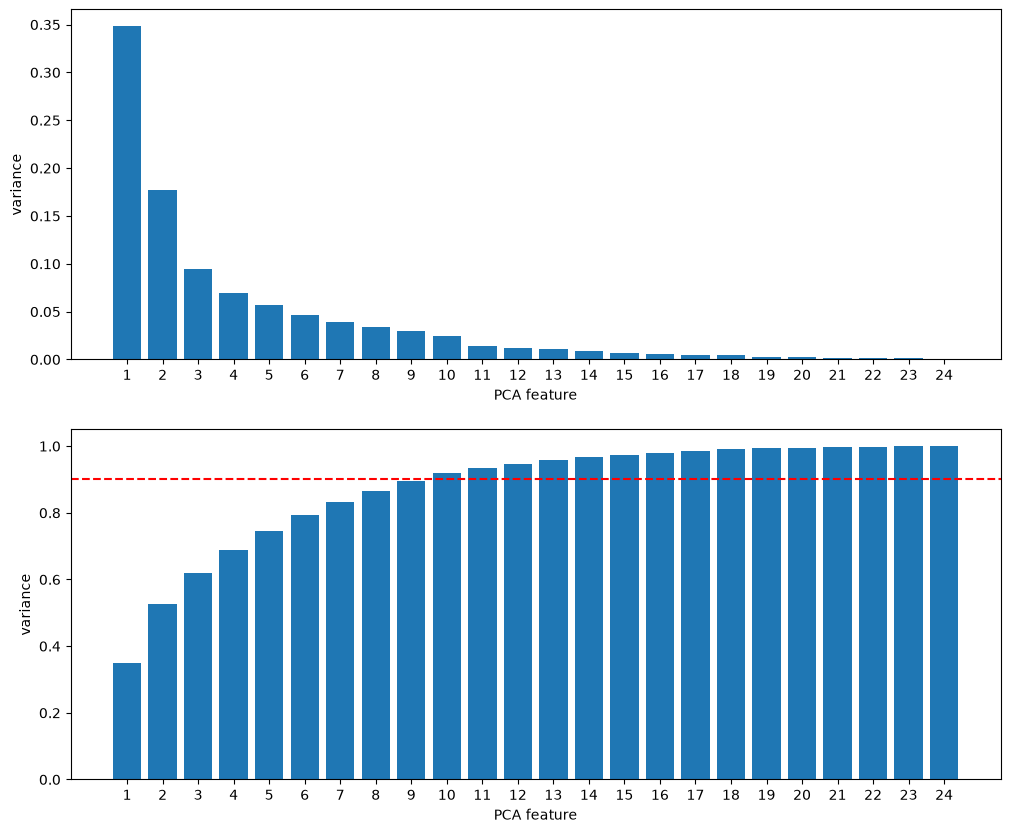

np.int64(10)

In [50]:
from sklearn.decomposition import PCA
# TODO (a)
#Ver gráficamente cuantas CP hacen falta. 
PCA_modelo = PCA()
PCA_modelo.fit(H)
features = range(1,PCA_modelo.n_components_ + 1)
Varianza_explicada = PCA_modelo.explained_variance_ratio_
Varianza_explicada_acumulada = np.cumsum(Varianza_explicada)
fig, axs = plt.subplots(2, 1, figsize=(12, 10))
axs[0].bar(features, Varianza_explicada )
axs[0].set_xticks(features)
axs[0].set_ylabel('variance')
axs[0].set_xlabel('PCA feature')
axs[1].bar(features, Varianza_explicada_acumulada)
axs[1].set_xticks(features)
axs[1].axhline(y=0.90, color='r', linestyle='--', label='90% de Varianza')
axs[1].set_ylabel('variance')
axs[1].set_xlabel('PCA feature')
plt.show()


#Manera analítica de verlo 
num_componentes_90 = np.argmax(Varianza_explicada_acumulada >= 0.90) + 1
num_componentes_90




**TODO (b).** El mapa de los cuadros en CP1–CP2 con `mapa_con_miniaturas`, y las **cargas** de
CP1 y CP2 como un diagrama de barras con los colores del diccionario.

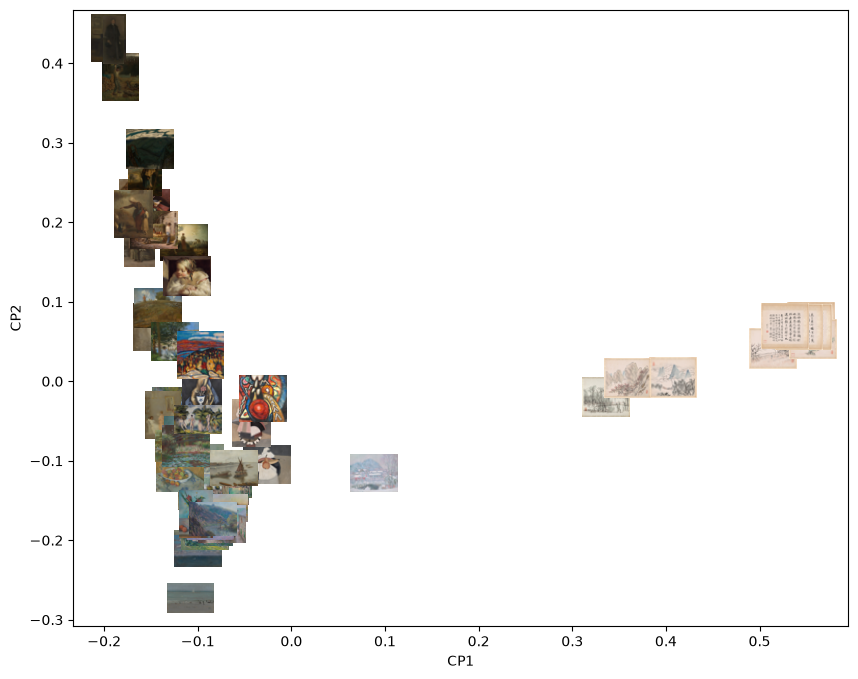

Text(0, 0.5, 'Proporciones')

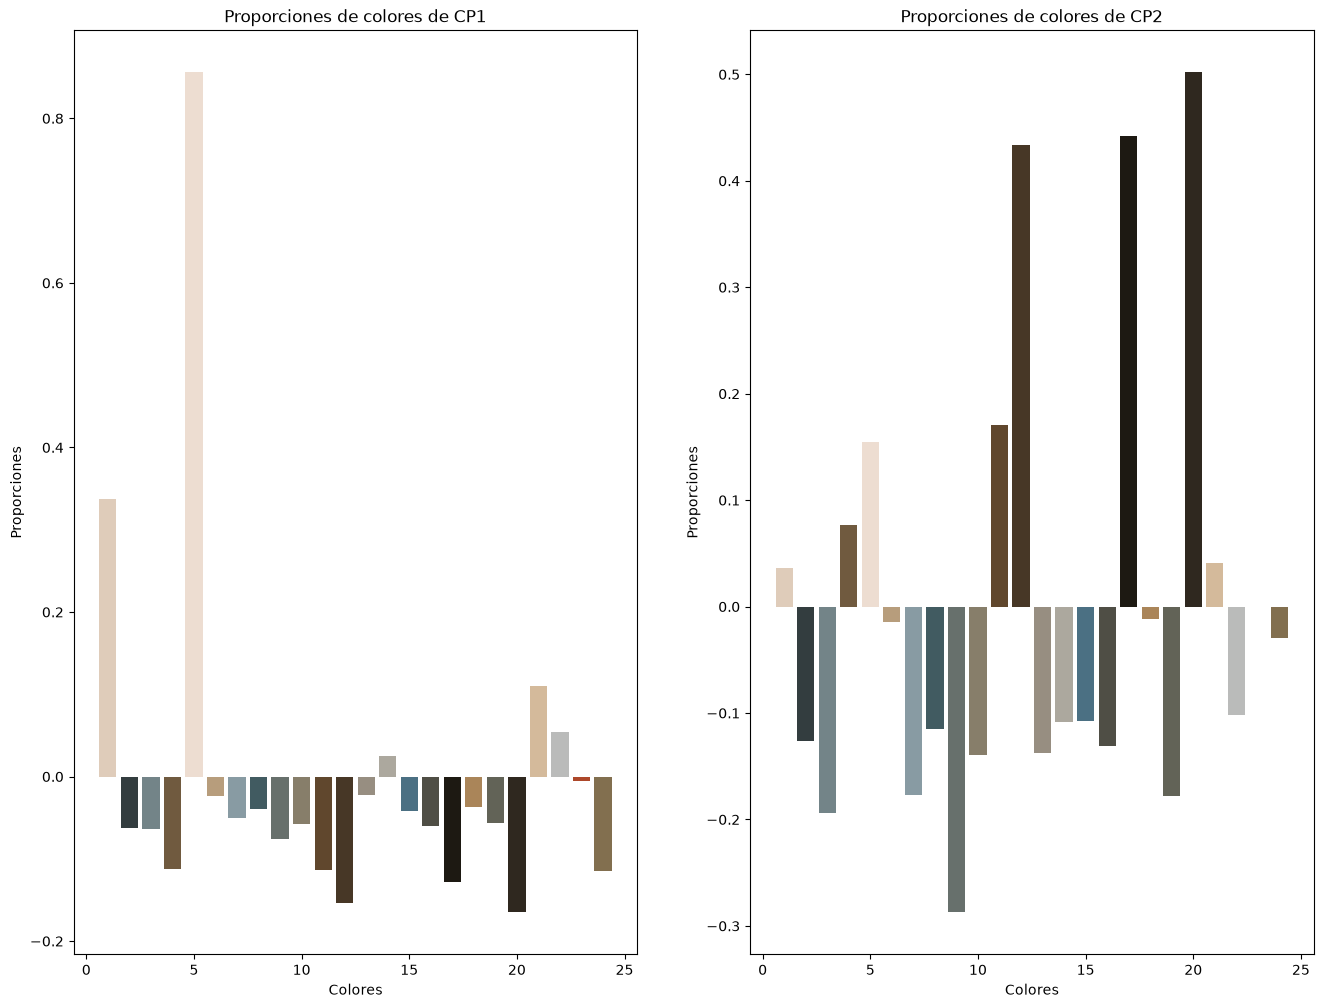

In [60]:
H_PCA = PCA_modelo.transform(H)


S = H_PCA[:, :2] 


CP1 = PCA_modelo.components_[0]
CP2 = PCA_modelo.components_[1]
mapa_con_miniaturas(S,cuadros["fichero"])



fig, axs = plt.subplots(1, 2, figsize=(16, 12))
axs[0].bar(range(1,25),CP1, color = modelo_KMeans.cluster_centers_)
axs[1].bar(range(1,25),CP2, color = modelo_KMeans.cluster_centers_)
axs[0].set_title("Proporciones de colores de CP1")
axs[1].set_title("Proporciones de colores de CP2")
axs[0].set_xlabel("Colores")
axs[1].set_xlabel("Colores")
axs[0].set_ylabel("Proporciones")
axs[1].set_ylabel("Proporciones")
#plt.title("Histograma de proporciones de colores en el diccionario K=24")
#plt.xlabel("Proporción de color")

**TODO (c).** Interpretad CP1 y CP2 **con palabras de color**, a partir de las cargas. Después
coloread el marco de cada miniatura por autor (ya revelado) y relacionad las tres cosas:
componentes, grupos de vuestra partición congelada y autores.

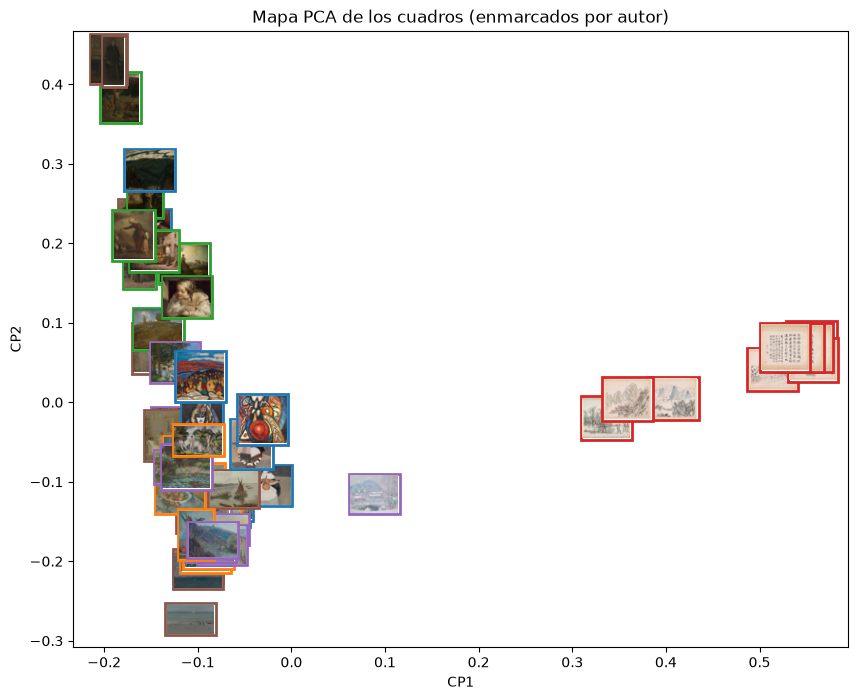

In [69]:
# TODO (c)

autores_unicos = y_autor.unique()
paleta = plt.get_cmap("tab10")
colores_marco = [paleta(list(autores_unicos).index(autor)) for autor in y_autor]
mapa_con_miniaturas(S, cuadros["fichero"], 
                    titulo="Mapa PCA de los cuadros (enmarcados por autor)", 
                    etiquetas_ejes=("CP1", "CP2"), 
                    lado=46, 
                    colores_marco=colores_marco)



---
## Antes de entregar

1. **Reiniciad el núcleo y ejecutad todas las celdas de arriba abajo, en una sola pasada.**
   Guardad con las salidas.
2. Ejecutad la comprobación del sello sobre el fichero guardado.
3. Renombrad el fichero como `p1_grupo<N>.ipynb`, con vuestro número de grupo.
4. Entregad el cuaderno y `USO_IA.md`.

In [ ]:
# Comprobación del sello. Apuntadla al fichero GUARDADO.
# check_seal(f"p1_grupo{GRUPO}.ipynb")